# DSGym Paper Plots — DSPredict-Hard, per Variant

Self-contained notebook (does **not** import `app.py`/streamlit). Loads DSPredict-**Hard**
runs from the classic `*_results.json` files **plus** the per-task intermediate files that carry
the prompt variants (adaptive-revision, vanilla, problem-decomposition, data-quality-methods,
expert-agentic, reasoning-only/nodags seeds).

It produces **one figure per Variant**, plotting that variant against the model's plain `dags` and
`nodags` baselines, across a consistent set of metrics.

Edit the `VARIANTS` list / `METRICS` list below to add or drop variants/metrics. `SHOW` controls
which variants get a figure.

In [1]:
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

RESULTS_DIR = Path(".")   # this notebook lives in evaluation_results/

MODEL_LABELS = {
    "claude-sonnet-4-5": "Claude Sonnet 4.5",
    "claude-sonnet-4-6": "Claude Sonnet 4.6",
    "gpt-5.1":           "GPT-5.1",
    "gpt-4o-mini":       "GPT-4o Mini",
    "gpt-4o":            "GPT-4o",
    "gpt-5":             "GPT-5",
    "deepseek-v4-pro":   "DeepSeek V4 Pro",
    "kimi-k2p7-code":    "Kimi K2 Code",
    "sonnet-4-5":        "Sonnet 4.5",
    "Qwen3-Coder-480B-A35B-Instruct-FP8": "Qwen3 480B",
    "Qwen3-Coder-480B":  "Qwen3 Coder 480B",
}

N_PROBLEMS = 54        # DSPredict-Hard task count (used by the "paper" above-median)

# ---- Editable model filter: which base models appear in the plots. ----------
#   None                    -> show every model that has data
#   ["gpt-4o-mini", "..."]  -> only these base-models are plotted
MODELS_SHOWN = None

# ---- Colour / hatch scheme ----
DAG_COLOR   = "#2196F3"    # plain dags baseline
NODAG_COLOR = "#FF9800"    # plain nodags baseline
NODAG_HATCH = "////"       # hatch marks any No-DAG series

# One entry per Variant figure. 'seed': None  -> non-seed runs;
# 'seed': "42" -> only the seed-42 runs of that mode.
VARIANTS = [
    {"mode": "dags_adaptive-revision",         "label": "Adaptive Revision",     "color": "#4CAF50"},
    {"mode": "dags_vanilla-no-implementation", "label": "Vanilla",               "color": "#9C27B0"},
    {"mode": "dags_problem-decomposition",     "label": "Problem Decomposition", "color": "#E53935"},
    {"mode": "dags_problem-decomposition",     "label": "Problem Decomposition (seed)", "color": "#E53935", "seed": "42"},
    {"mode": "dags_data-quality-methods",      "label": "Data Quality",          "color": "#00897B"},
    {"mode": "dags_expert-agentic",            "label": "Expert Agentic",        "color": "#D81B60"},
    {"mode": "dags_expert-agentic",            "label": "Expert Agentic (seed)",        "color": "#D81B60", "seed": "42"},
    {"mode": "dags_reasoning-only",            "label": "Reasoning-only (seed)", "color": "#8D6E63", "seed": "42"},
    {"mode": "nodags",                         "label": "No-DAG (seed)",         "color": "#546E7A", "seed": "42"},
    {"mode": "dags",                           "label": "DAG (seed)",            "color": "#42A5F5", "seed": "42"},
]

SHOW = VARIANTS   # comment out any entries here to skip their figure

# Metrics: (key, y-label, title, is-percentage?). 'pct' rows get a fixed 0-100 axis.
METRICS = [
    ("coverage",             "Coverage (%)",       "% tasks completed",            True),
    ("above_med",            "Above-median (%)",   "% COMPLETE above PUBLIC median", True),
    ("above_med_paper",      "Above-median (%)",   "above PUBLIC median / all tasks (paper)", True),
    ("medal_rate",           "Medal Rate (%)",     "% tasks w/ PUBLIC medal",      True),
    ("avg_pub_pct",          "Avg public pct",     "mean PUBLIC percentile",       False),
    ("avg_priv_pct",         "Avg private pct",    "mean PRIVATE percentile",      False),
    ("above_med_priv",       "Above-median (%)",   "% COMPLETE above PRIVATE median", True),
    ("above_med_priv_paper", "Above-median (%)",   "above PRIVATE median / all tasks (paper)", True),
    ("medal_rate_priv",      "Medal Rate (%)",     "% tasks w/ PRIVATE medal",     True),
    ("avg_out_tok",          "Avg output tokens",  "mean output tokens / 1000",    False),
]
PCT_KEYS = {k for k, _y, _t, p in METRICS if p}

In [2]:
# ------------------------- helpers (mirror app.py) -------------------------
def _slug_to_name(raw: str) -> str:
    name = raw.replace("_", "-")
    name = re.sub(r"\bgpt-(\d+)-(\d+)\b", r"gpt-\1.\2", name)
    return name

_DAG_MODE_LABELS = {
    "dags": None,
    "dags_adaptive-revision": "adaptive",
    "dags_vanilla-no-implementation": "vanilla",
    "dags_problem-decomposition": "problem decomposition",
    "dags_data-quality-methods": "data quality",
    "dags_expert-agentic": "expert agentic",
    "dags_reasoning-only": "reasoning-only",
    "nodags": "nodags",
}

def _parse_dag_slug(slug):
    seed = None; s = slug
    m = re.search(r"_seed\d+$", s)
    if m:
        seed = s[m.start() + len("_seed"):]; s = s[:m.start()]
    for mode in _DAG_MODE_LABELS:
        suf = f"_{mode}"
        if s.endswith(suf):
            return s[:-len(suf)], mode, seed
    return None

def _dag_model_label(base, mode, seed):
    name = _slug_to_name(base); lab = _DAG_MODE_LABELS.get(mode)
    if lab: name += f" ({lab})"
    if seed is not None: name += f" seed{seed}"
    return name

def _is_collected_dag_slug(slug):
    p = _parse_dag_slug(slug)
    if not p: return False
    _b, mode, seed = p
    if mode == "nodags" and seed is None: return False
    return True

# ------------------- discovery: results files (Hard only) -------------------
_KNOWN_MODES = ["dags_vanilla-no-implementation", "dags_adaptive-revision",
                "dags_problem-decomposition", "dags_data-quality-methods", "dags_expert-agentic",
                "dags_reasoning-only", "dags", "nodags"]
_KNOWN_PROVIDERS = ["fireworks_ai_", "fireworks_Qwen_", "fireworks_", "openai_"]

def _discover_results_hard():
    runs = {}
    for fpath in sorted(RESULTS_DIR.glob("*_results.json")):
        name = fpath.name
        if name.startswith("daeval_"): continue
        m = re.match(r"^(.+?)_litellm_(.+?)_results\.json$", name)
        if not m: continue
        benchmark, rest = m.group(1), m.group(2)
        if benchmark != "dspredict-hard": continue     # Hard only
        mode = None
        for cnd in _KNOWN_MODES:
            if rest.endswith(f"_{cnd}"): mode = cnd; rest = rest[:-(len(cnd) + 1)]; break
        model = rest
        for prov in _KNOWN_PROVIDERS:
            if model.startswith(prov): model = model[len(prov):]; break
        if mode == "dags_adaptive-revision":             model = f"{model} (adaptive)"
        elif mode == "dags_vanilla-no-implementation":   model = f"{model} (vanilla)"
        elif mode == "dags_problem-decomposition":        model = f"{model} (problem decomposition)"
        elif mode == "dags_data-quality-methods":         model = f"{model} (data quality)"
        elif mode == "dags_expert-agentic":               model = f"{model} (expert agentic)"
        runs[(model, mode if mode else "nodags")] = fpath
    return runs

# ------------------- discovery: per-task intermediate files -------------------
def _discover_dag_model_configs():
    slug_set = set()
    for f in RESULTS_DIR.iterdir():
        if f.suffix != ".json": continue
        m = re.match(r"^.+?_\d+_(.+)$", f.stem)
        if not m: continue
        slug = m.group(1)
        if _is_collected_dag_slug(slug): slug_set.add(slug)
    configs = {}
    for slug in sorted(slug_set):
        p = _parse_dag_slug(slug)
        if not p: continue
        base, mode, seed = p
        configs[_dag_model_label(base, mode, seed)] = {"suffix": f"_{slug}.json"}
    return configs

def _discover_per_task_hard(existing_hard, configs):
    slug_files = {}
    for f in sorted(RESULTS_DIR.iterdir()):
        if f.suffix != ".json": continue
        m = re.match(r"^.+?_\d+_(.+)$", f.stem)
        if not m: continue
        slug = m.group(1)
        if _is_collected_dag_slug(slug): slug_files.setdefault(slug, []).append(f)
    extra = {}
    for slug, files in slug_files.items():
        suffix = f"_{slug}.json"
        model_name = next((m for m, cc in configs.items() if cc["suffix"] == suffix), None)
        if model_name is None: continue
        parsed = _parse_dag_slug(slug)
        if parsed is None: continue
        mode = parsed[1]
        key = (model_name, mode)
        if key in existing_hard: continue
        try:
            sid = json.load(open(files[0])).get("sample_id", "") or ""
        except Exception:
            continue
        if not sid.startswith("dsbio_"):   # DSPredict per-task runs
            extra[key] = files
    return extra

# ------------------- per-item parse + load -------------------
SKIP_LB = {"public_scores", "private_scores", "scores"}

def _patch_per_task_item(raw, fname):
    m = re.match(r"^(.+?)_\d+_.+$", fname)
    comp = m.group(1) if m else None
    ks = (raw.get("metrics") or {}).get("kaggle_submission") or {}
    det = ks.get("details") or {}
    if not det.get("challenge_name") and comp:
        raw = dict(raw); raw["metrics"] = dict(raw.get("metrics") or {})
        raw["metrics"]["kaggle_submission"] = dict(ks)
        raw["metrics"]["kaggle_submission"]["details"] = dict(det)
        raw["metrics"]["kaggle_submission"]["details"]["challenge_name"] = comp
    return raw

def _parse_dp_item(item):
    ks = item.get("metrics", {}).get("kaggle_submission", {})
    det = ks.get("details") or {}
    lb = det.get("leaderboard_stats", {}) if isinstance(det, dict) else {}
    for k in SKIP_LB: lb.pop(k, None)
    tok = item.get("token_usage") or {}
    return {
        "sample_id":      item.get("sample_id"),
        "challenge":      det.get("challenge_name") if isinstance(det, dict) else None,
        "status":         (det.get("status", "") if isinstance(det, dict) else ""),
        "score":          ks.get("score"),
        "public_medal":   det.get("public_medal", "none") if isinstance(det, dict) else "none",
        "private_medal":  det.get("private_medal", "none") if isinstance(det, dict) else "none",
        "pub_percentile": det.get("public_percentile") if isinstance(det, dict) else None,
        "priv_percentile":det.get("private_percentile") if isinstance(det, dict) else None,
        "pub_above_med":  det.get("public_above_median") if isinstance(det, dict) else None,
        "priv_above_med": det.get("private_above_median") if isinstance(det, dict) else None,
        "pub_rank":       det.get("public_rank") if isinstance(det, dict) else None,
        "priv_rank":      det.get("private_rank") if isinstance(det, dict) else None,
        "execution_time": item.get("execution_time"),
        "total_turns":    item.get("total_turns"),
        "trajectory":     item.get("trajectory", []),
        "output_tokens":  tok.get("output_tokens"),
        "total_tokens":   tok.get("total_tokens"),
    }

def _load_run(val):
    if isinstance(val, (Path, str)):
        p = Path(val)
        if not p.exists(): return []
        with open(p) as f: return [_parse_dp_item(i) for i in json.load(f)]
    # list of per-task paths: dedupe by comp (lowest index first)
    slug_re = re.compile(r"^(.+?)_\d+_")
    seen, items = set(), []
    for p in sorted(val):
        m = slug_re.match(p.name); comp = m.group(1) if m else p.name
        if comp in seen: continue
        seen.add(comp)
        try: items.append(_parse_dp_item(_patch_per_task_item(json.load(open(p)), p.name)))
        except Exception: pass
    return items

hard_runs = _discover_results_hard()
configs   = _discover_dag_model_configs()
hard_runs.update(_discover_per_task_hard(hard_runs, configs))

dp_hard = {}
for key, val in hard_runs.items():
    rows = _load_run(val)
    if rows: dp_hard[key] = rows

# Mirror app.py: back gpt-4o-mini plain dags/nodags with the real per-task seed runs
for (_mdl, _mode, _pat) in [("gpt-4o-mini", "dags",   "*_gpt_4o_mini_dags_seed42.json"),
                            ("gpt-4o-mini", "nodags", "*_gpt_4o_mini_nodags_seed42.json")]:
    _k = (_mdl, _mode)
    if _k in dp_hard:
        _fs = sorted(RESULTS_DIR.glob(_pat))
        if _fs:
            dp_hard[_k] = _load_run(_fs)   # NOTE: parse paths -> row dicts

# ---- base-model mapping (group a variant's runs to its baselines) ----
_BASE_TOKENS = set(_slug_to_name(b) for b in MODEL_LABELS)
for (m, md) in dp_hard.keys():
    _BASE_TOKENS.add(m.split(" (")[0].split(" seed")[0])
_BASE_TOKENS = sorted(_BASE_TOKENS, key=len, reverse=True)

def base_of(model_name):
    for b in _BASE_TOKENS:
        if model_name == b or model_name.startswith(b):
            return b
    return model_name

def variant_key(base, spec):
    want = None
    for (m, mode) in dp_hard.keys():
        if mode != spec["mode"]: continue
        if base_of(m) != base: continue
        has_seed = (" seed" in m)
        if spec.get("seed") is None and has_seed: continue
        if spec.get("seed") is not None and f"seed{spec['seed']}" not in m: continue
        want = m          # (prefer the primary run for this mode)
    return want

print(f"DSPredict-Hard runs: {len(dp_hard)}")
for (m, mode) in sorted(dp_hard.keys()):
    print(f"  {mode:34} {m:44} N={len(dp_hard[(m, mode)])}")

DSPredict-Hard runs: 26
  dags                               Qwen3-Coder-480B-A35B-Instruct               N=10
  dags                               Qwen3-Coder-480B-A35B-Instruct-FP8           N=54
  dags                               claude-sonnet-4-5                            N=54
  dags                               claude-sonnet-4-6                            N=10
  dags                               deepseek-v4-pro                              N=54
  dags_adaptive-revision             deepseek-v4-pro (adaptive)                   N=54
  dags_expert-agentic                glm-5p2 (expert agentic) seed42              N=54
  dags_adaptive-revision             gpt-4o (adaptive)                            N=2
  dags                               gpt-4o-mini                                  N=53
  nodags                             gpt-4o-mini                                  N=54
  dags_adaptive-revision             gpt-4o-mini (adaptive)                       N=54
  dags_adaptive-revi

In [3]:
# ------------------------- metric definitions -------------------------
def _cov(data):
    sub = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    return 100 * len(sub) / max(1, len(data))

def _above(data):            # % COMPLETE above PUBLIC median
    vs = [r["pub_above_med"] for r in data if r.get("pub_above_med") is not None]
    return 100 * sum(vs) / len(vs) if vs else 0.0

def _above_paper(data):      # above PUBLIC median / all tasks (original-paper metric)
    vs = [r["pub_above_med"] for r in data if r.get("pub_above_med") is not None]
    return 100 * sum(vs) / N_PROBLEMS if data else 0.0

def _above_priv(data):       # % COMPLETE above PRIVATE median
    vs = [r["priv_above_med"] for r in data if r.get("priv_above_med") is not None]
    return 100 * sum(vs) / len(vs) if vs else 0.0

def _above_priv_paper(data): # above PRIVATE median / all tasks
    vs = [r["priv_above_med"] for r in data if r.get("priv_above_med") is not None]
    return 100 * sum(vs) / N_PROBLEMS if data else 0.0

def _medal_rate(data):       # % tasks with a PUBLIC medal
    sub = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    med = [r for r in sub if r.get("public_medal") not in (None, "none")]
    return 100 * len(med) / max(1, len(data))

def _medal_rate_priv(data):  # % tasks with a PRIVATE medal
    sub = [r for r in data if "COMPLETE" in str(r.get("status", ""))]
    med = [r for r in sub if r.get("private_medal") not in (None, "none")]
    return 100 * len(med) / max(1, len(data))

def _avg_pub(data):
    v = [r["pub_percentile"] for r in data if r.get("pub_percentile") is not None]
    return float(np.mean(v)) if v else 0.0

def _avg_priv(data):
    v = [r["priv_percentile"] for r in data if r.get("priv_percentile") is not None]
    return float(np.mean(v)) if v else 0.0

def _avg_out(data):
    v = [r["output_tokens"] for r in data if r.get("output_tokens") is not None]
    return float(np.mean(v)) / 1_000 if v else 0.0

METRIC_FN = {
    "coverage": _cov, "above_med": _above, "above_med_paper": _above_paper,
    "medal_rate": _medal_rate, "avg_pub_pct": _avg_pub, "avg_priv_pct": _avg_priv,
    "above_med_priv": _above_priv, "above_med_priv_paper": _above_priv_paper,
    "medal_rate_priv": _medal_rate_priv, "avg_out_tok": _avg_out,
}

def _apply_models_show(bases):
    """Restrict a list of base-model tokens to MODELS_SHOWN if it is set."""
    if MODELS_SHOWN is None:
        return bases
    return [b for b in bases if b in MODELS_SHOWN]

# ------------------------- per-variant figure -------------------------
def plot_variant(spec, models=None):
    mode = spec["mode"]
    bases = sorted({base_of(m) for (m, md) in dp_hard.keys()
                    if md == mode and base_of(m) != m},
                   key=lambda b: MODEL_LABELS.get(b, b))
    if models is not None:
        bases = [b for b in bases if b in models]
    bases = _apply_models_show(bases)
    bases = [b for b in bases if variant_key(b, spec)]
    if not bases:
        print(f"  (no data) '{spec['label']}' — skipped.")
        return

    nmet = len(METRICS)
    ncols = 3; nrows = int(np.ceil(nmet / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.1 * nrows), squeeze=False)
    axes = [a for row in axes for a in row]
    group_w = 3.0
    sep_color = "#cccccc"

    def slots(base):
        vk = variant_key(base, spec)
        return [
            ("DAGs",       DAG_COLOR,   None,        dp_hard.get((base, "dags"),   [])),
            (spec["label"], spec["color"], None,    dp_hard.get(vk, []) if vk else []),
            ("No-DAG",     NODAG_COLOR, NODAG_HATCH, dp_hard.get((base, "nodags"), [])),
        ]

    for idx, (fkey, ylabel, title, _pct) in enumerate(METRICS):
        ax = axes[idx]
        fn = METRIC_FN[fkey]
        centers = []
        for gi, base in enumerate(bases):
            x0 = gi * group_w
            for j, (_lab, color, hatch, data) in enumerate(slots(base)):
                v = fn(data) if data else None
                if v is not None:
                    ax.bar(x0 + j, v, 0.85, color=color, hatch=hatch, edgecolor="white")
                    if v > 0:
                        ax.text(x0 + j, v + 0.5, f"{v:.1f}", ha="center", va="bottom", fontsize=7.5)
            centers.append(x0 + 1)
            if gi < len(bases) - 1:
                ax.axvline(x0 + group_w - 0.5, color=sep_color, lw=0.8, ls=":")
        ax.set_xticks(centers)
        ax.set_xticklabels([MODEL_LABELS.get(b, b) for b in bases], rotation=15, ha="right", fontsize=9)
        ax.set_ylabel(ylabel)
        ax.set_title(title, fontsize=10)
        if fkey in PCT_KEYS:
            ax.set_ylim(0, 100)

    for ax in axes[nmet:]:
        ax.axis("off")

    handles = [Patch(facecolor=DAG_COLOR, label="DAGs (baseline)"),
               Patch(facecolor=spec["color"], label=spec["label"]),
               Patch(facecolor=NODAG_COLOR, hatch=NODAG_HATCH, label="No-DAG (baseline)")]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=True, fontsize=10)
    fig.suptitle(f"DSPredict-Hard — {spec['label']}", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0.05, 1, 0.97])
    mode_clean = mode.replace("/", "_")
    seed_part = f"_seed{spec['seed']}" if spec.get("seed") is not None else ""
    fname = f"dspredict_hard_variant_{mode_clean}{seed_part}.png"
    fig.savefig(RESULTS_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved {fname}")

# ------------------------- baselines (dags vs nodags) figure -------------------------
def plot_baselines(models=None):
    """DAG-vs-No-DAG overview for every model that has plain dags/nodags runs."""
    bl = sorted({base_of(m) for (m, md) in dp_hard.keys() if md in ("dags", "nodags")},
                key=lambda b: MODEL_LABELS.get(b, b))
    if models is not None:
        bl = [b for b in bl if b in models]
    bl = _apply_models_show(bl)
    bl = [b for b in bl if dp_hard.get((b, "dags")) or dp_hard.get((b, "nodags"))]
    if not bl:
        print("  (no baselines) skipped."); return

    nmet = len(METRICS); ncols = 3; nrows = int(np.ceil(nmet / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(max(13, 1.7 * len(bl)), 3.1 * nrows), squeeze=False)
    axes = [a for row in axes for a in row]
    x = np.arange(len(bl)); w = 0.38
    for idx, (fkey, ylabel, title, _pct) in enumerate(METRICS):
        ax = axes[idx]; fn = METRIC_FN[fkey]
        dags_v = [fn(dp_hard.get((b, "dags"), [])) or None for b in bl]
        nod_v  = [fn(dp_hard.get((b, "nodags"), [])) or None for b in bl]
        b1 = ax.bar(x - w/2, [v if v is not None else 0 for v in dags_v], w, color=DAG_COLOR)
        b2 = ax.bar(x + w/2, [v if v is not None else 0 for v in nod_v],  w, color=NODAG_COLOR, hatch=NODAG_HATCH)
        ax.set_xticks(x)
        ax.set_xticklabels([MODEL_LABELS.get(b, b) for b in bl], rotation=25, ha="right", fontsize=9)
        ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)
        if fkey in PCT_KEYS: ax.set_ylim(0, 100)
        for bars, vals in ((b1, dags_v), (b2, nod_v)):
            for bar, val in zip(bars, vals):
                if val:
                    ax.text(bar.get_x() + bar.get_width()/2, val + 0.5, f"{val:.1f}",
                            ha="center", va="bottom", fontsize=7.5)
    for ax in axes[nmet:]: ax.axis("off")
    fig.legend(handles=[Patch(facecolor=DAG_COLOR, label="DAGs"),
                        Patch(facecolor=NODAG_COLOR, hatch=NODAG_HATCH, label="No-DAG")],
               loc="lower center", ncol=2, frameon=True, fontsize=10)
    fig.suptitle("DSPredict-Hard — Baselines (DAG vs No-DAG)", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0.05, 1, 0.97])
    fig.savefig(RESULTS_DIR / "dspredict_hard_baselines.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved dspredict_hard_baselines.png")

def plot_deltas(models=None):
    """DAG-vs-No-DAG deltas: performance (per metric) + medal-rate (per model)."""
    dm = sorted({base_of(m) for (m, md) in dp_hard.keys() if md in ("dags", "nodags")},
                key=lambda b: MODEL_LABELS.get(b, b))
    if models is not None:
        dm = [b for b in dm if b in models]
    dm = _apply_models_show(dm)
    dm = [b for b in dm if dp_hard.get((b, "dags")) and dp_hard.get((b, "nodags"))]
    if not dm:
        print("  (no dags+nodags pairs) skipped."); return

    # performance delta per (model, metric)
    m_labels, deltas = [], []
    for b in dm:
        dg, nd = dp_hard[(b, "dags")], dp_hard[(b, "nodags")]
        for fkey, _ylab, title, _pct in METRICS:
            fn = METRIC_FN[fkey]
            vg, vn = fn(dg), fn(nd)
            if vg == vn == 0:      # no usable data on either side
                continue
            m_labels.append(f"{MODEL_LABELS.get(b, b)}\n{title}")
            deltas.append(vg - vn)

    med_d = [(_medal_rate(dp_hard[(b, 'dags')]) - _medal_rate(dp_hard[(b, 'nodags')])) for b in dm]

    n_y = max(len(m_labels), len(dm))
    fig, axes = plt.subplots(1, 2, figsize=(max(15, 1.5 * len(m_labels)), max(5, 0.33 * n_y)))
    # Left: performance delta
    ax = axes[0]
    cols = ["#2196F3" if d >= 0 else "#F44336" for d in deltas]
    y = np.arange(len(m_labels))
    ax.barh(y, deltas, color=cols, alpha=0.85)
    ax.set_yticks(y); ax.set_yticklabels(m_labels, fontsize=6.5)
    ax.set_xlabel("$\Delta$ = DAGs $-$ No-DAGs  (positive $\\rightarrow$ DAG better)")
    ax.set_title("Performance Delta by Metric")
    ax.axvline(0, color="black", lw=1)
    for i, d in enumerate(deltas):
        ax.text(d + (0.2 if d >= 0 else -0.2), i, f"{d:+.1f}", va="center",
                ha="left" if d >= 0 else "right", fontsize=6)
    # Right: medal-rate delta
    ax2 = axes[1]
    mcl = ["#2196F3" if d >= 0 else "#F44336" for d in med_d]
    y2 = np.arange(len(dm))
    ax2.barh(y2, med_d, color=mcl, alpha=0.85)
    ax2.set_yticks(y2); ax2.set_yticklabels([MODEL_LABELS.get(b, b) for b in dm], fontsize=9)
    ax2.set_xlabel("$\Delta$ = DAGs $-$ No-DAGs  (pp)")
    ax2.set_title("Medal-Rate Delta (DAG $-$ No-DAG)")
    ax2.axvline(0, color="black", lw=1)
    for i, d in enumerate(med_d):
        ax2.text(d + (0.3 if d >= 0 else -0.3), i, f"{d:+.1f}", va="center",
                 ha="left" if d >= 0 else "right", fontsize=9)

    fig.suptitle("DSPredict-Hard — DAG vs No-DAG Deltas", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(RESULTS_DIR / "dspredict_hard_delta.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved dspredict_hard_delta.png")

<>:198: SyntaxWarning: invalid escape sequence '\D'
<>:210: SyntaxWarning: invalid escape sequence '\D'
<>:198: SyntaxWarning: invalid escape sequence '\D'
<>:210: SyntaxWarning: invalid escape sequence '\D'
/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_16133/2873134328.py:198: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel("$\Delta$ = DAGs $-$ No-DAGs  (positive $\\rightarrow$ DAG better)")
/var/folders/8g/0gjzsnd56wj1d38gd7pnnglw0000gp/T/ipykernel_16133/2873134328.py:210: SyntaxWarning: invalid escape sequence '\D'
  ax2.set_xlabel("$\Delta$ = DAGs $-$ No-DAGs  (pp)")


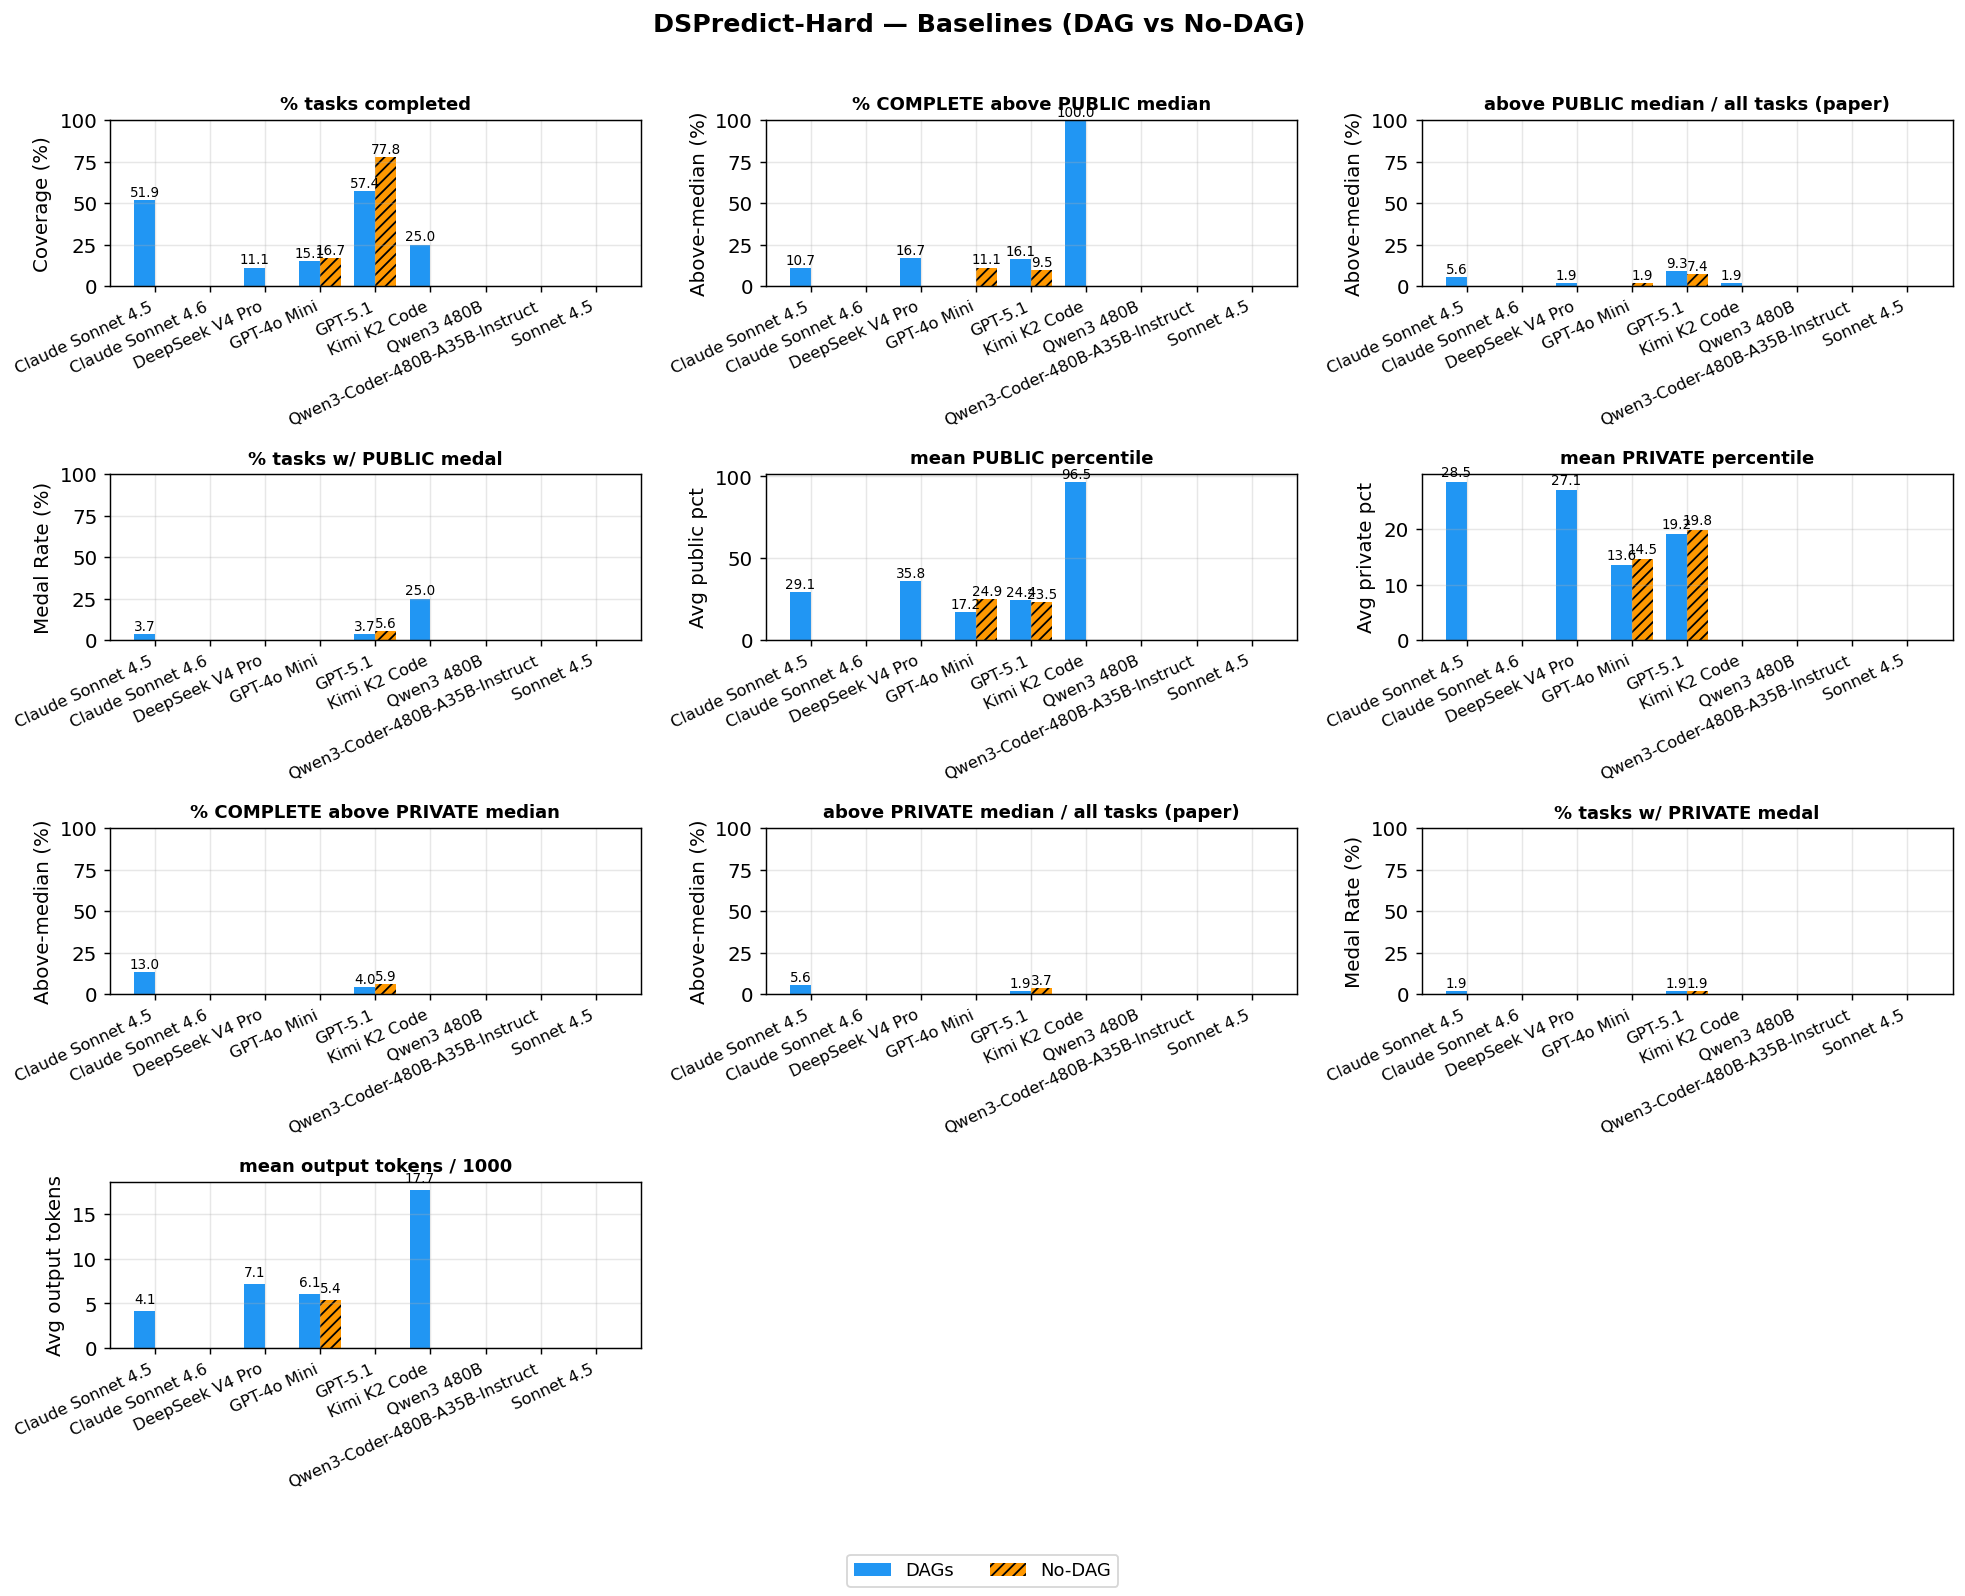

Saved dspredict_hard_baselines.png



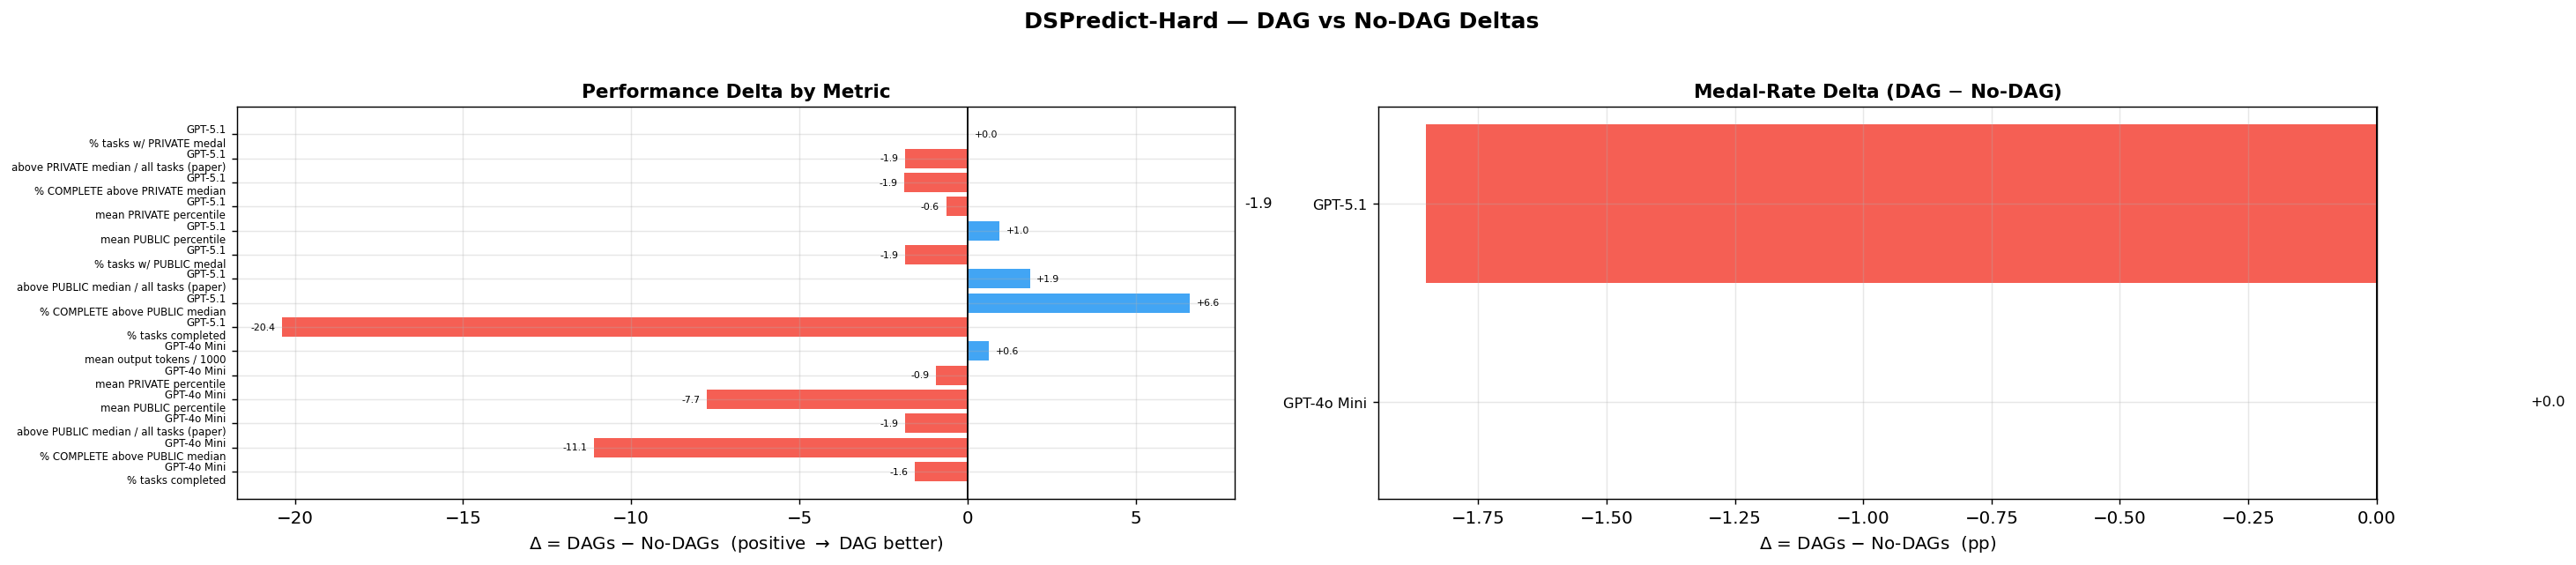

Saved dspredict_hard_delta.png



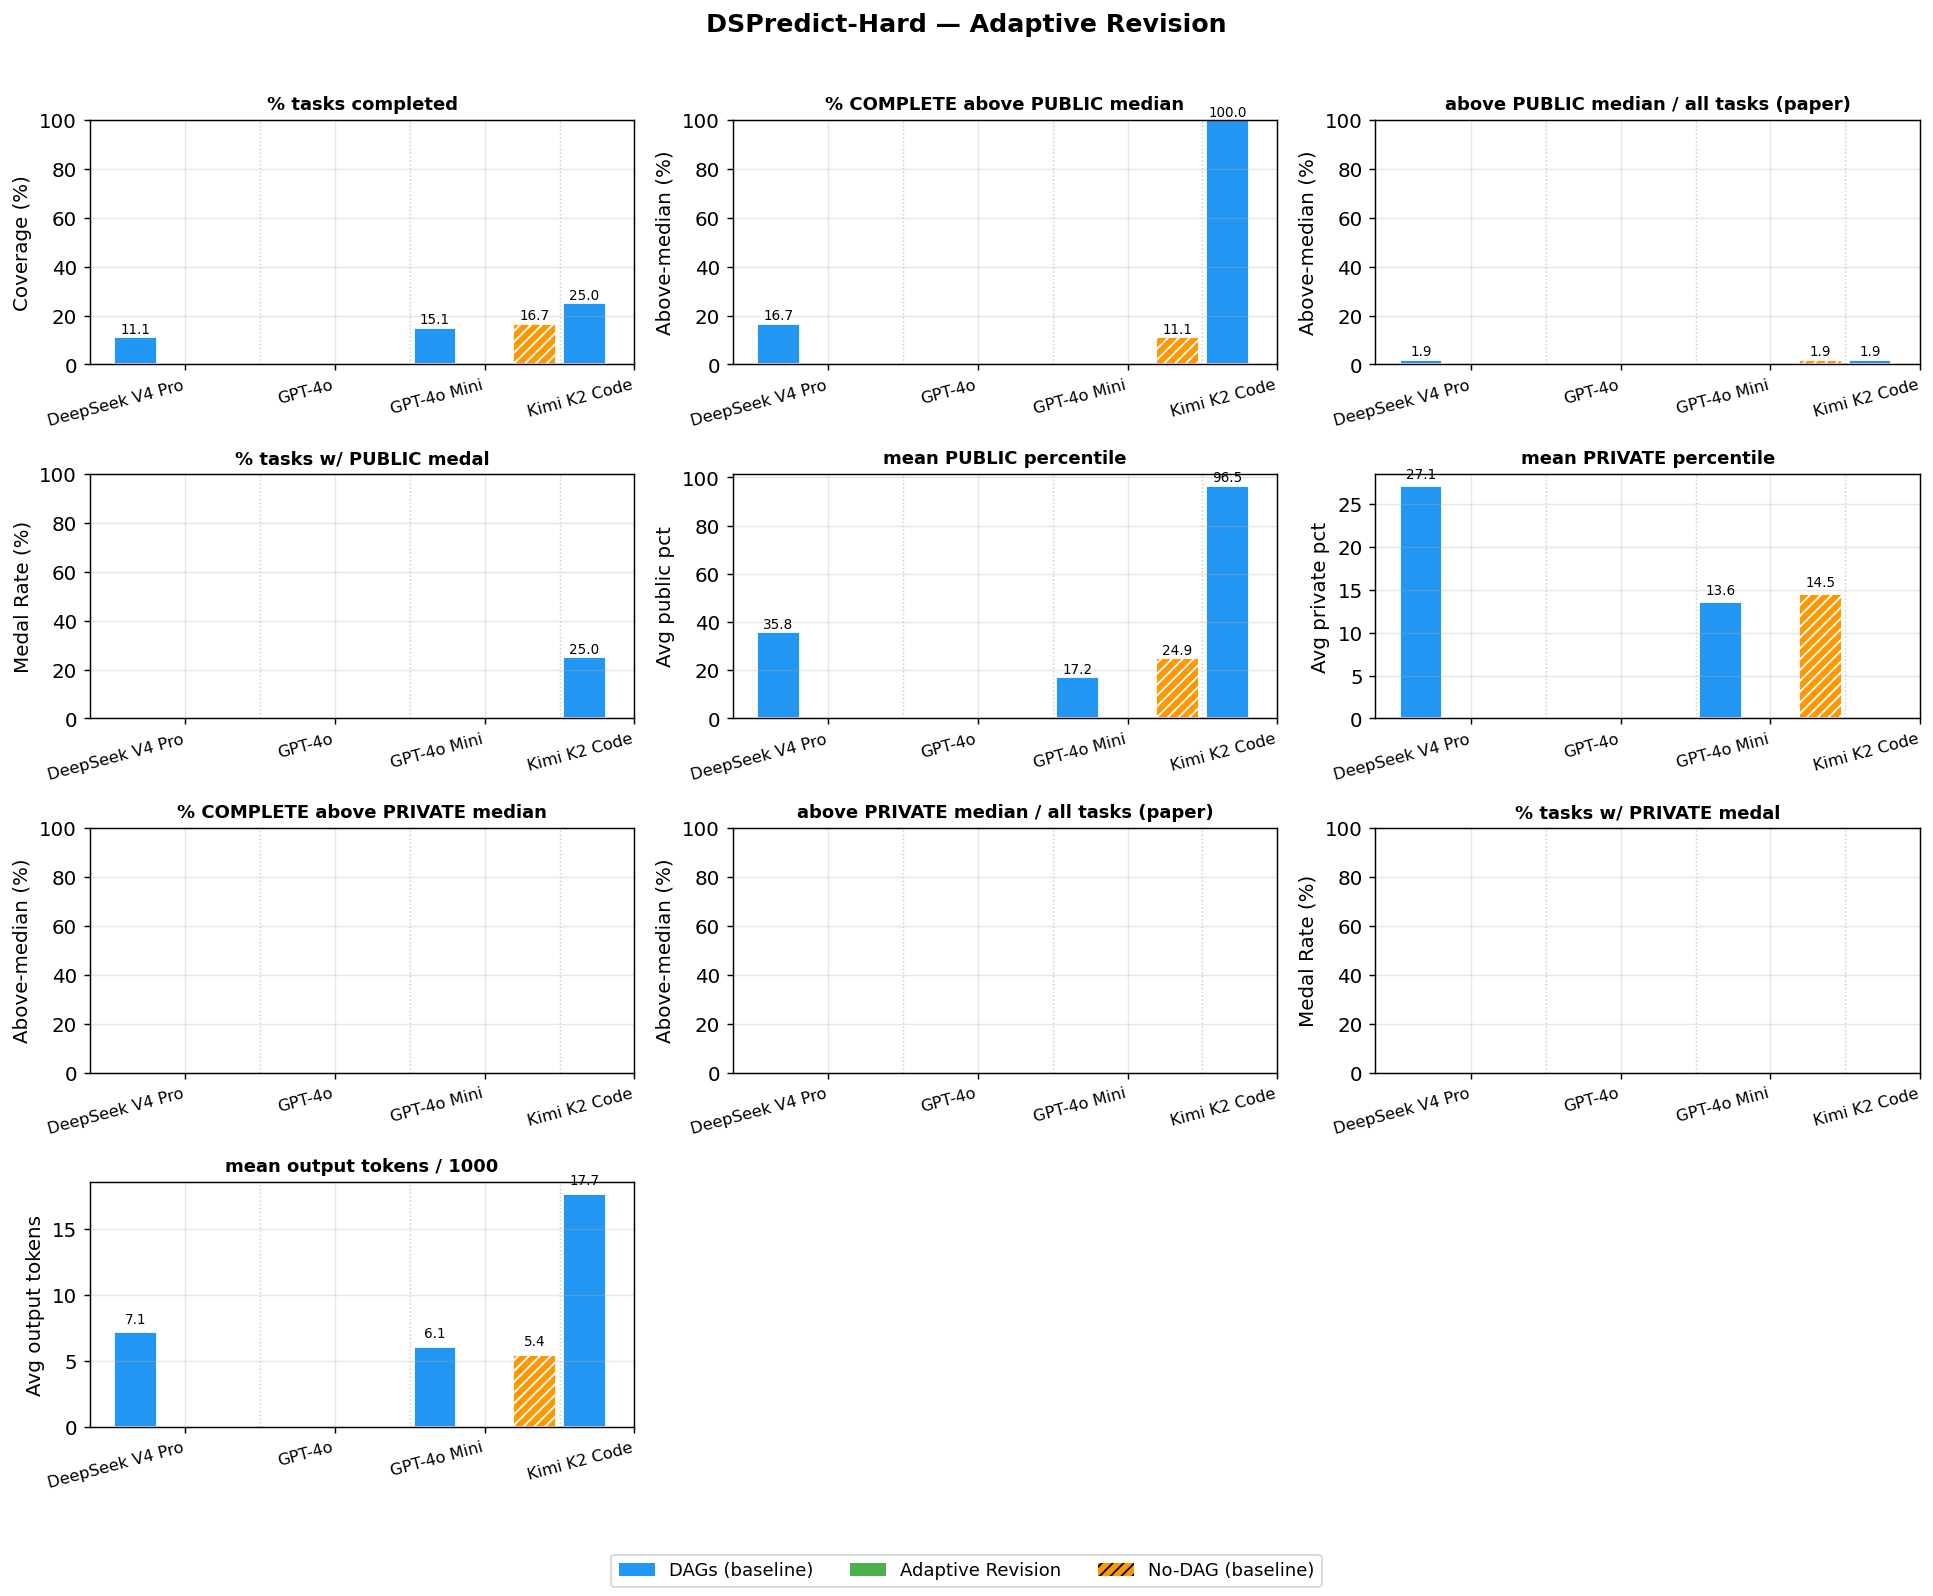

Saved dspredict_hard_variant_dags_adaptive-revision.png



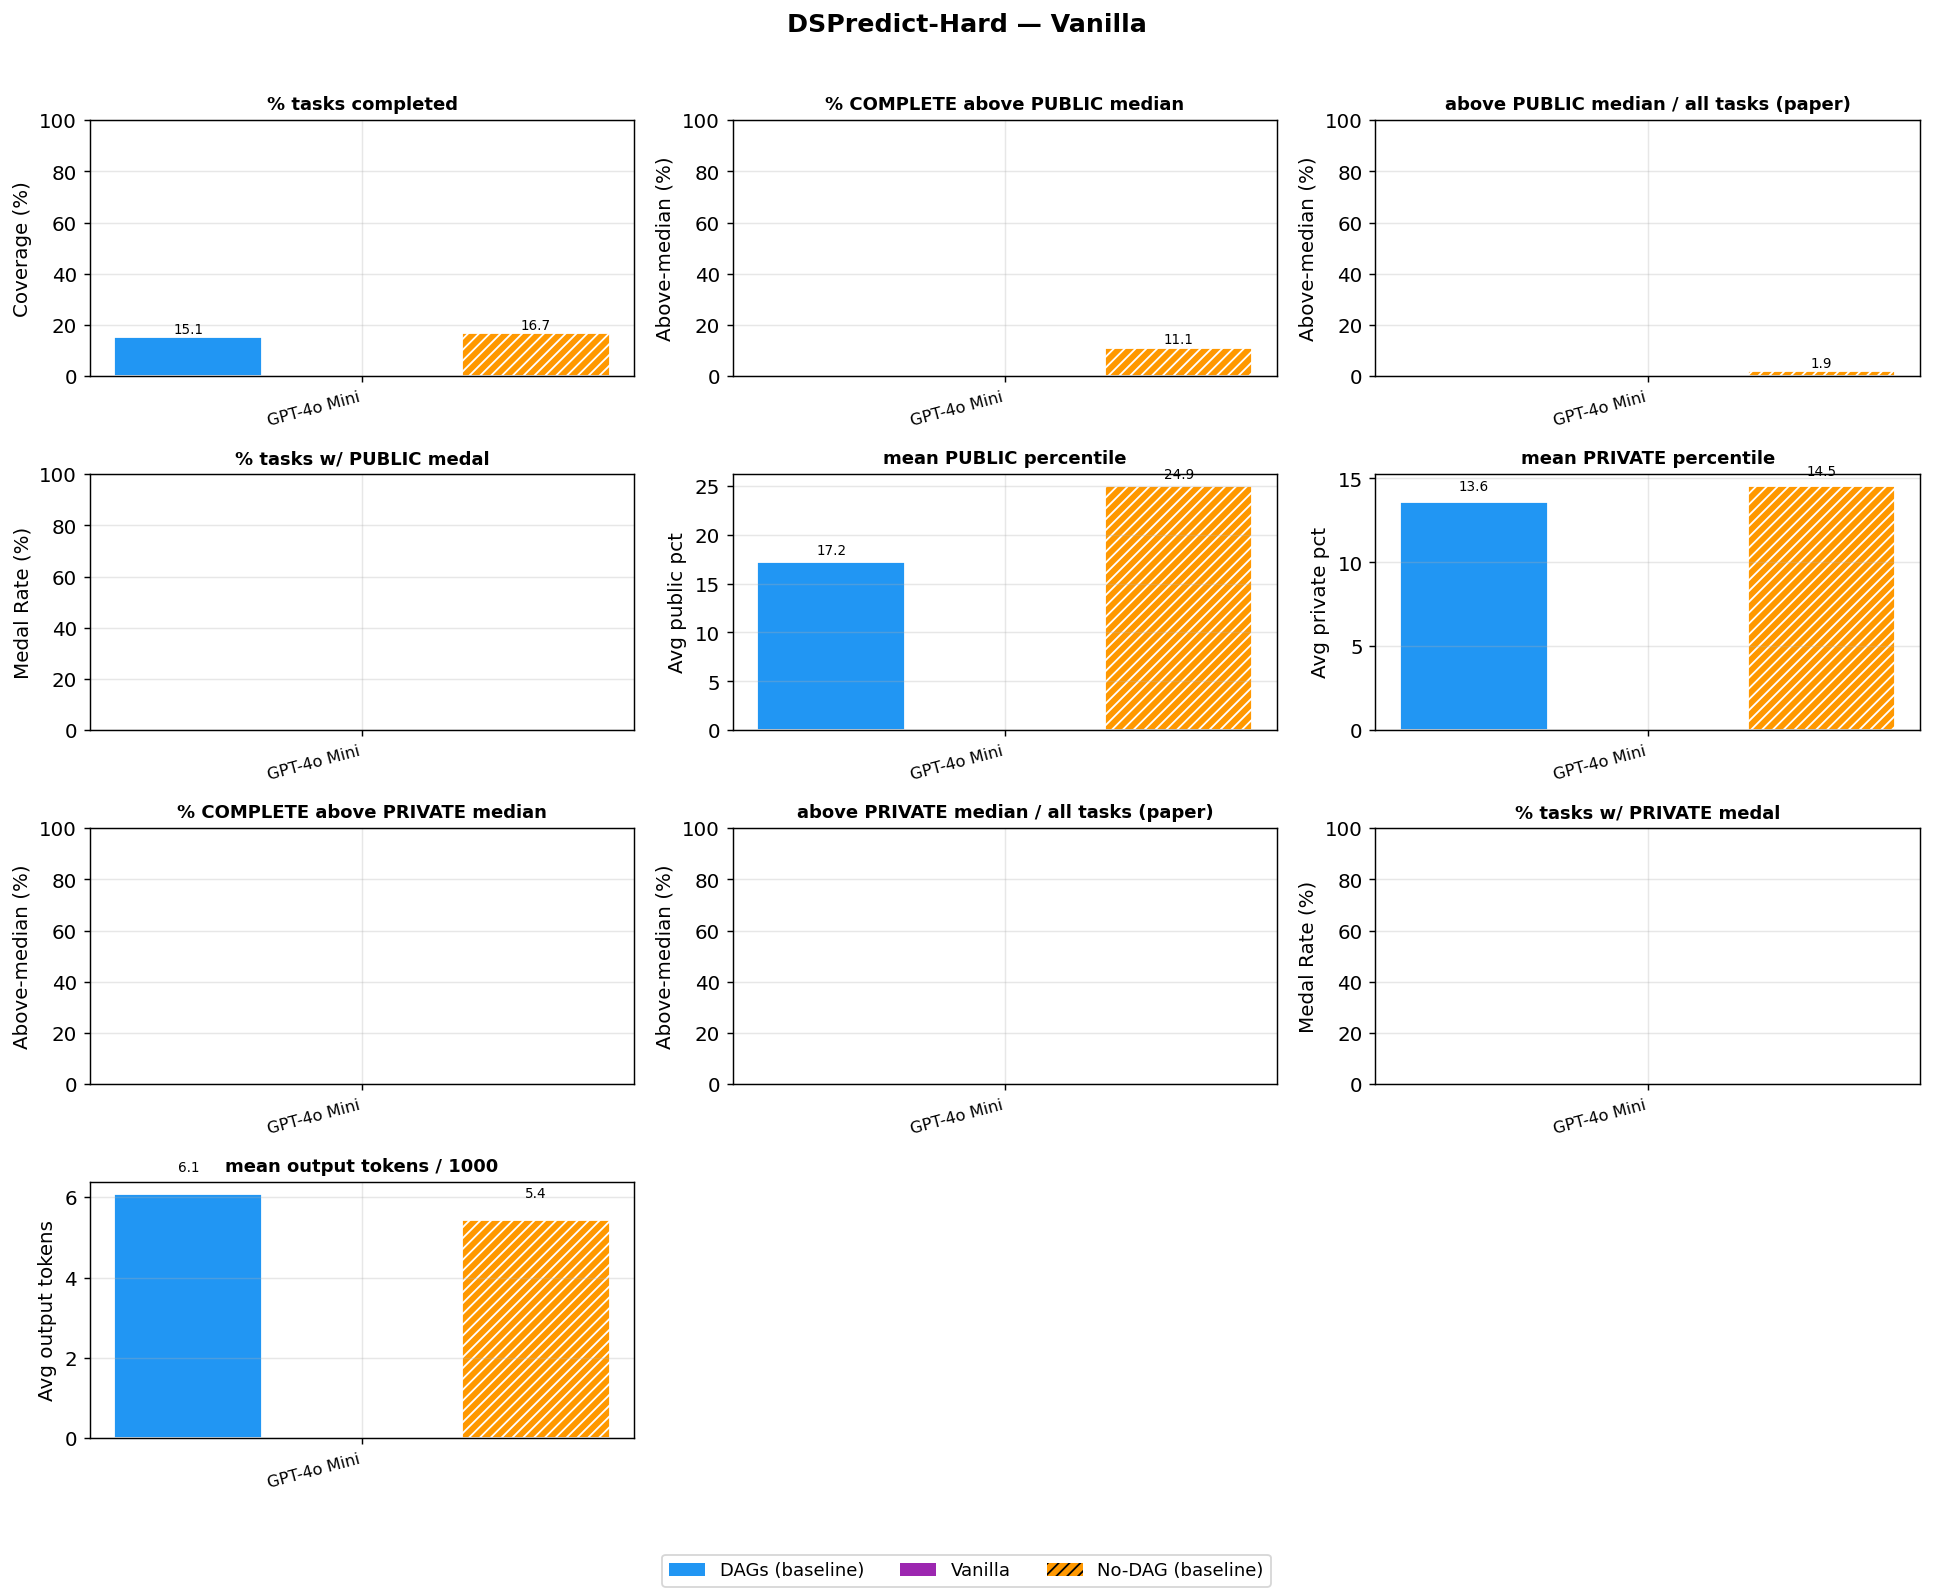

Saved dspredict_hard_variant_dags_vanilla-no-implementation.png



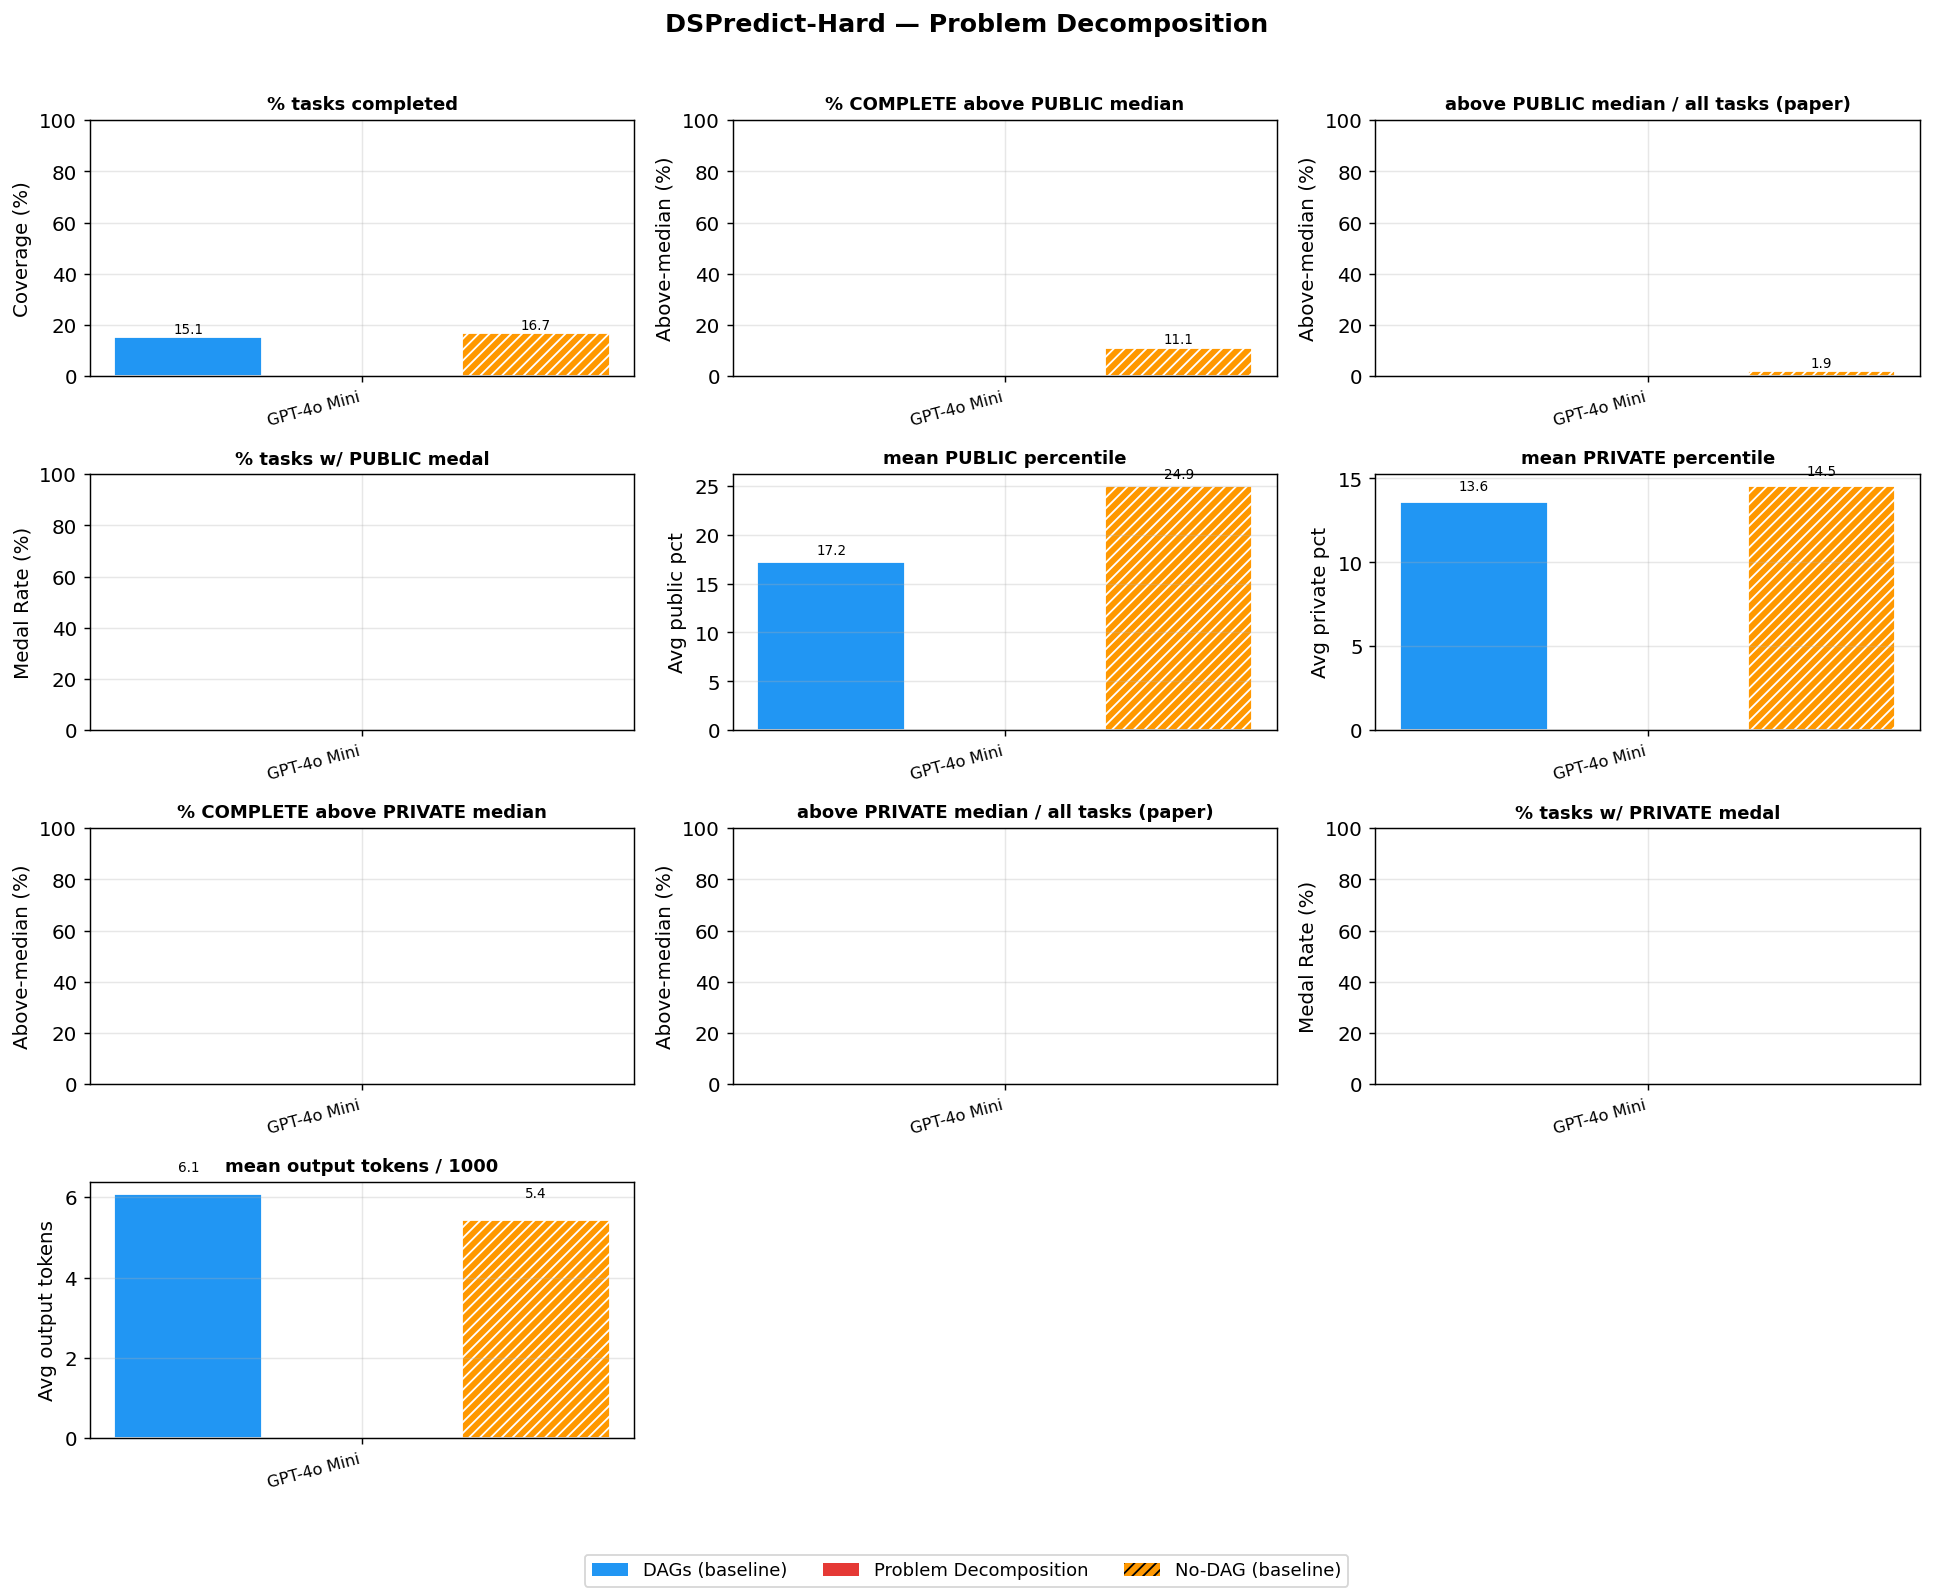

Saved dspredict_hard_variant_dags_problem-decomposition.png



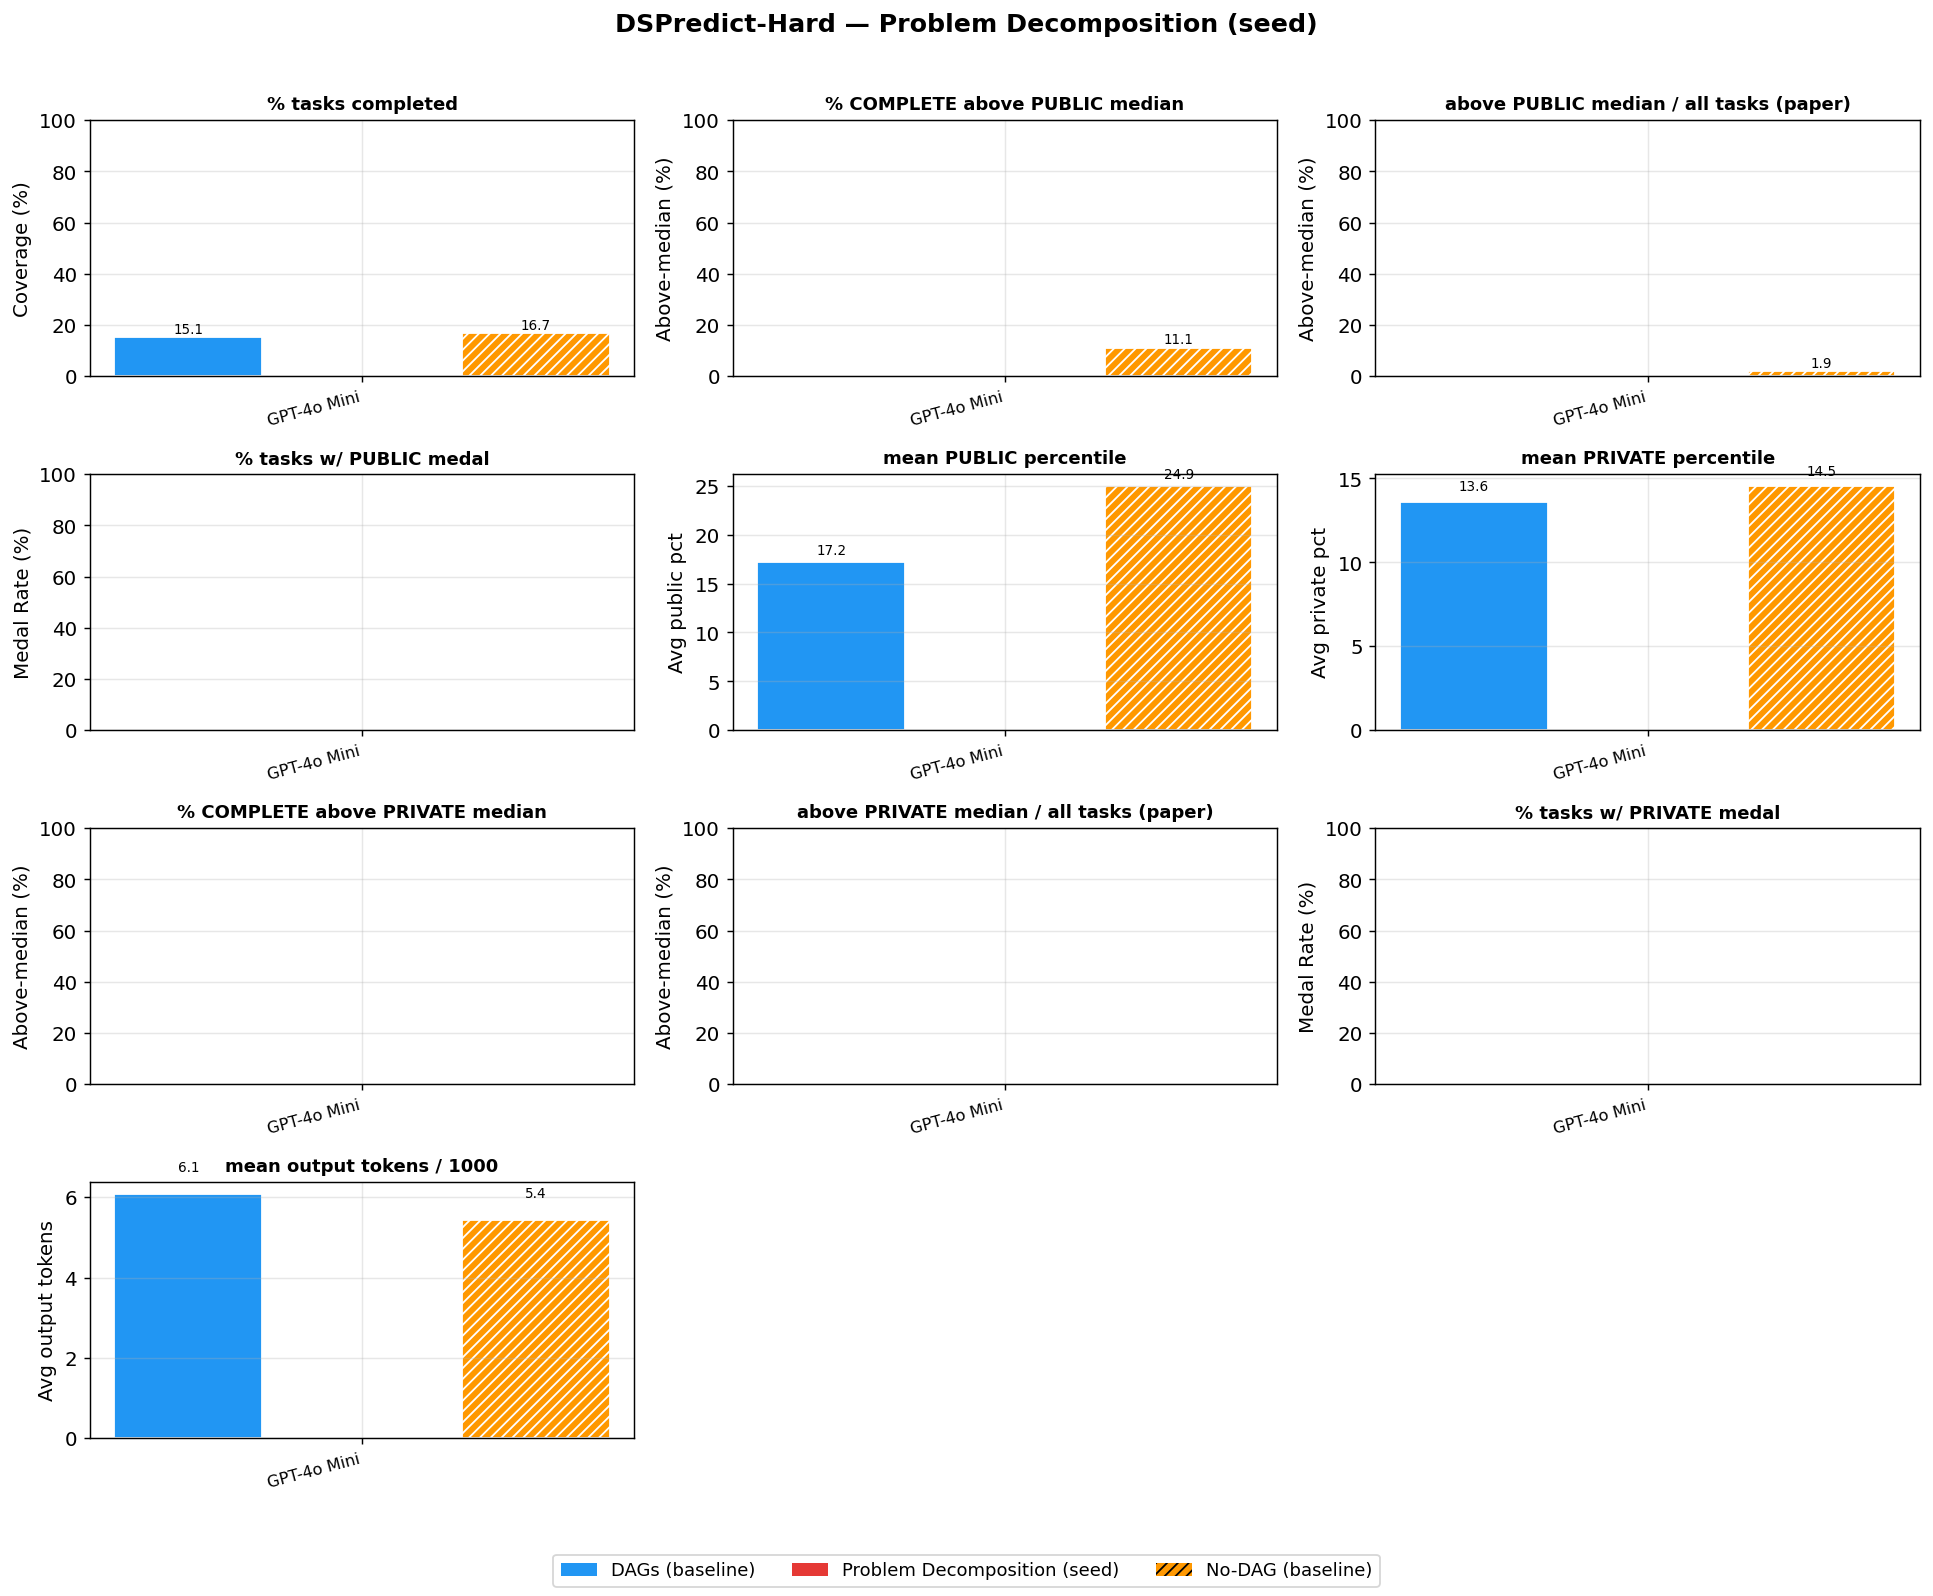

Saved dspredict_hard_variant_dags_problem-decomposition_seed42.png



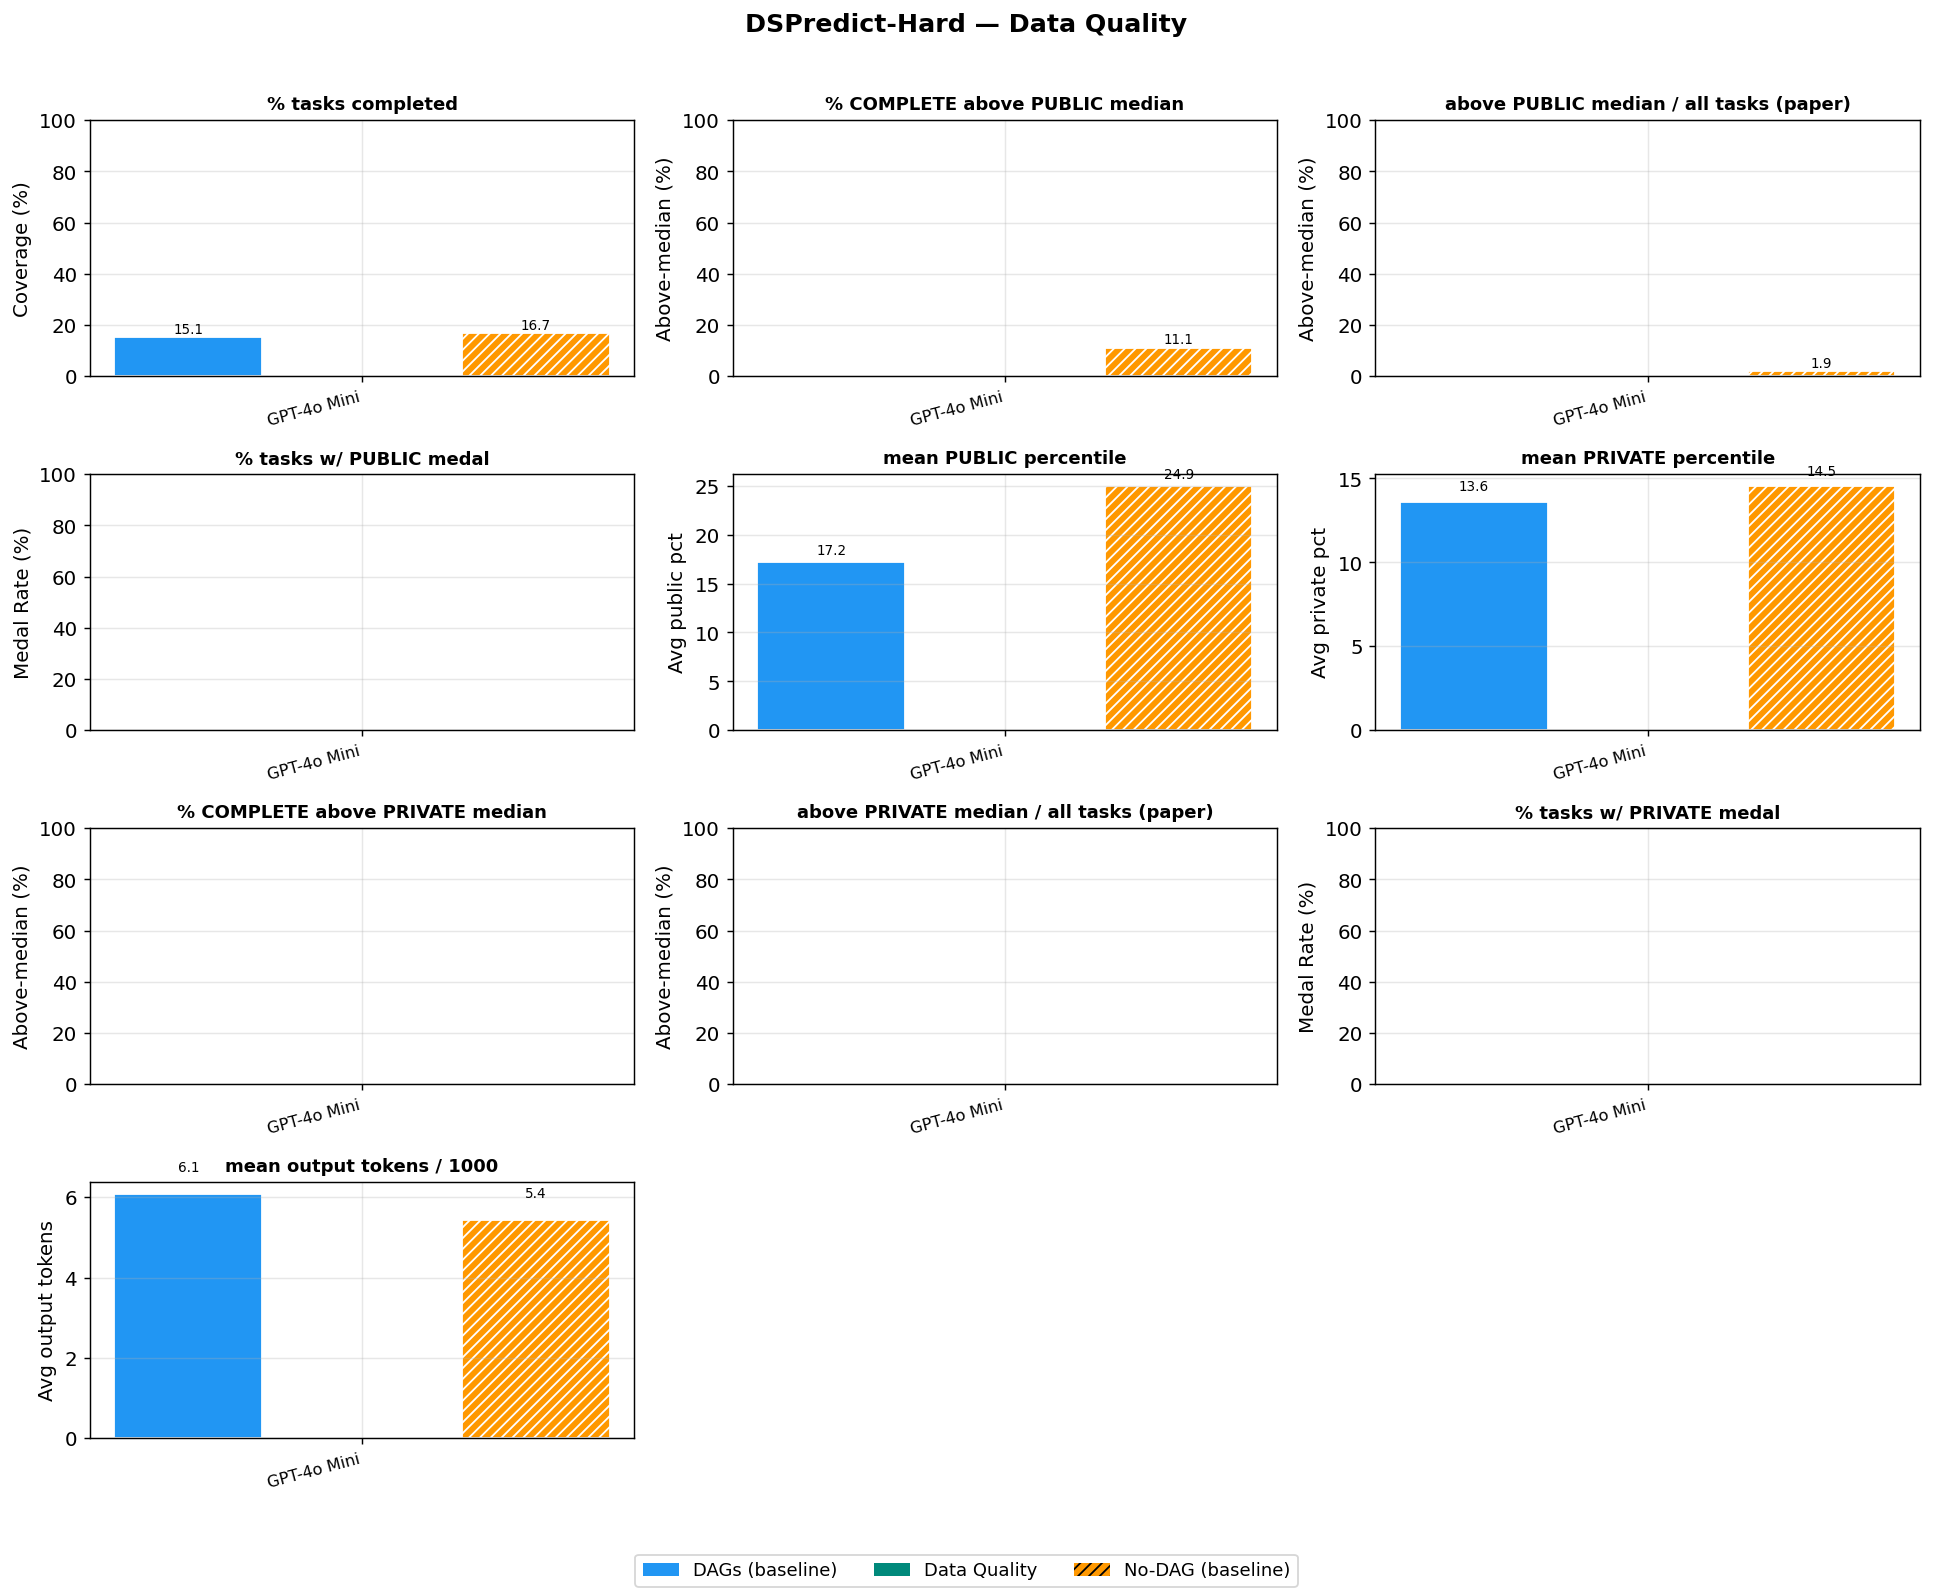

Saved dspredict_hard_variant_dags_data-quality-methods.png



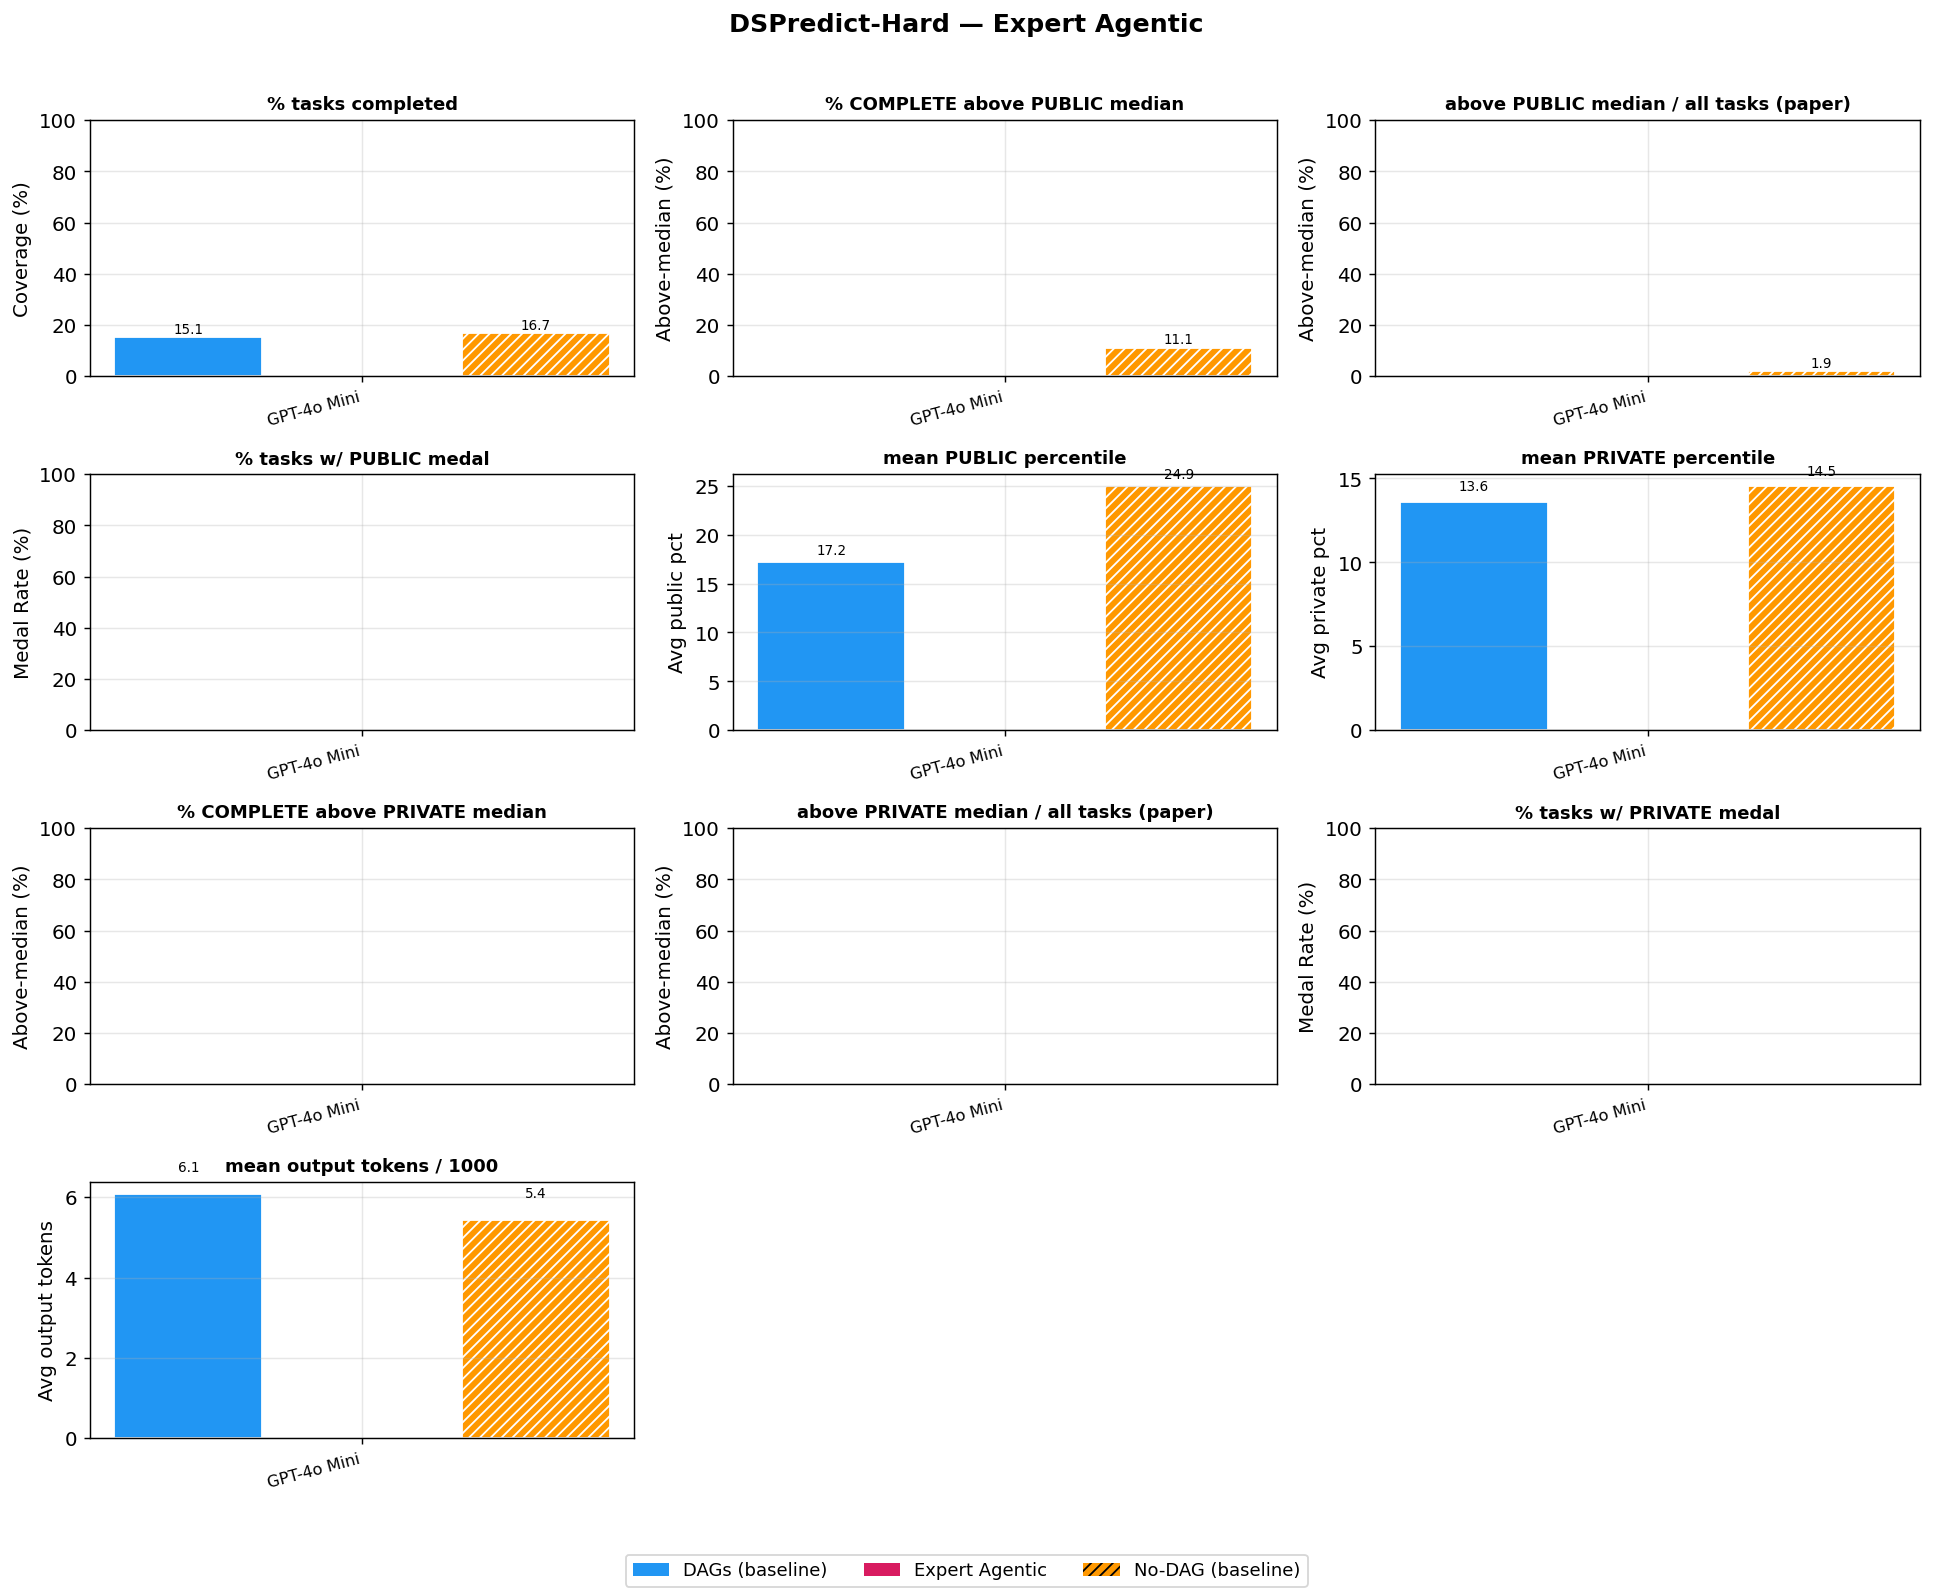

Saved dspredict_hard_variant_dags_expert-agentic.png



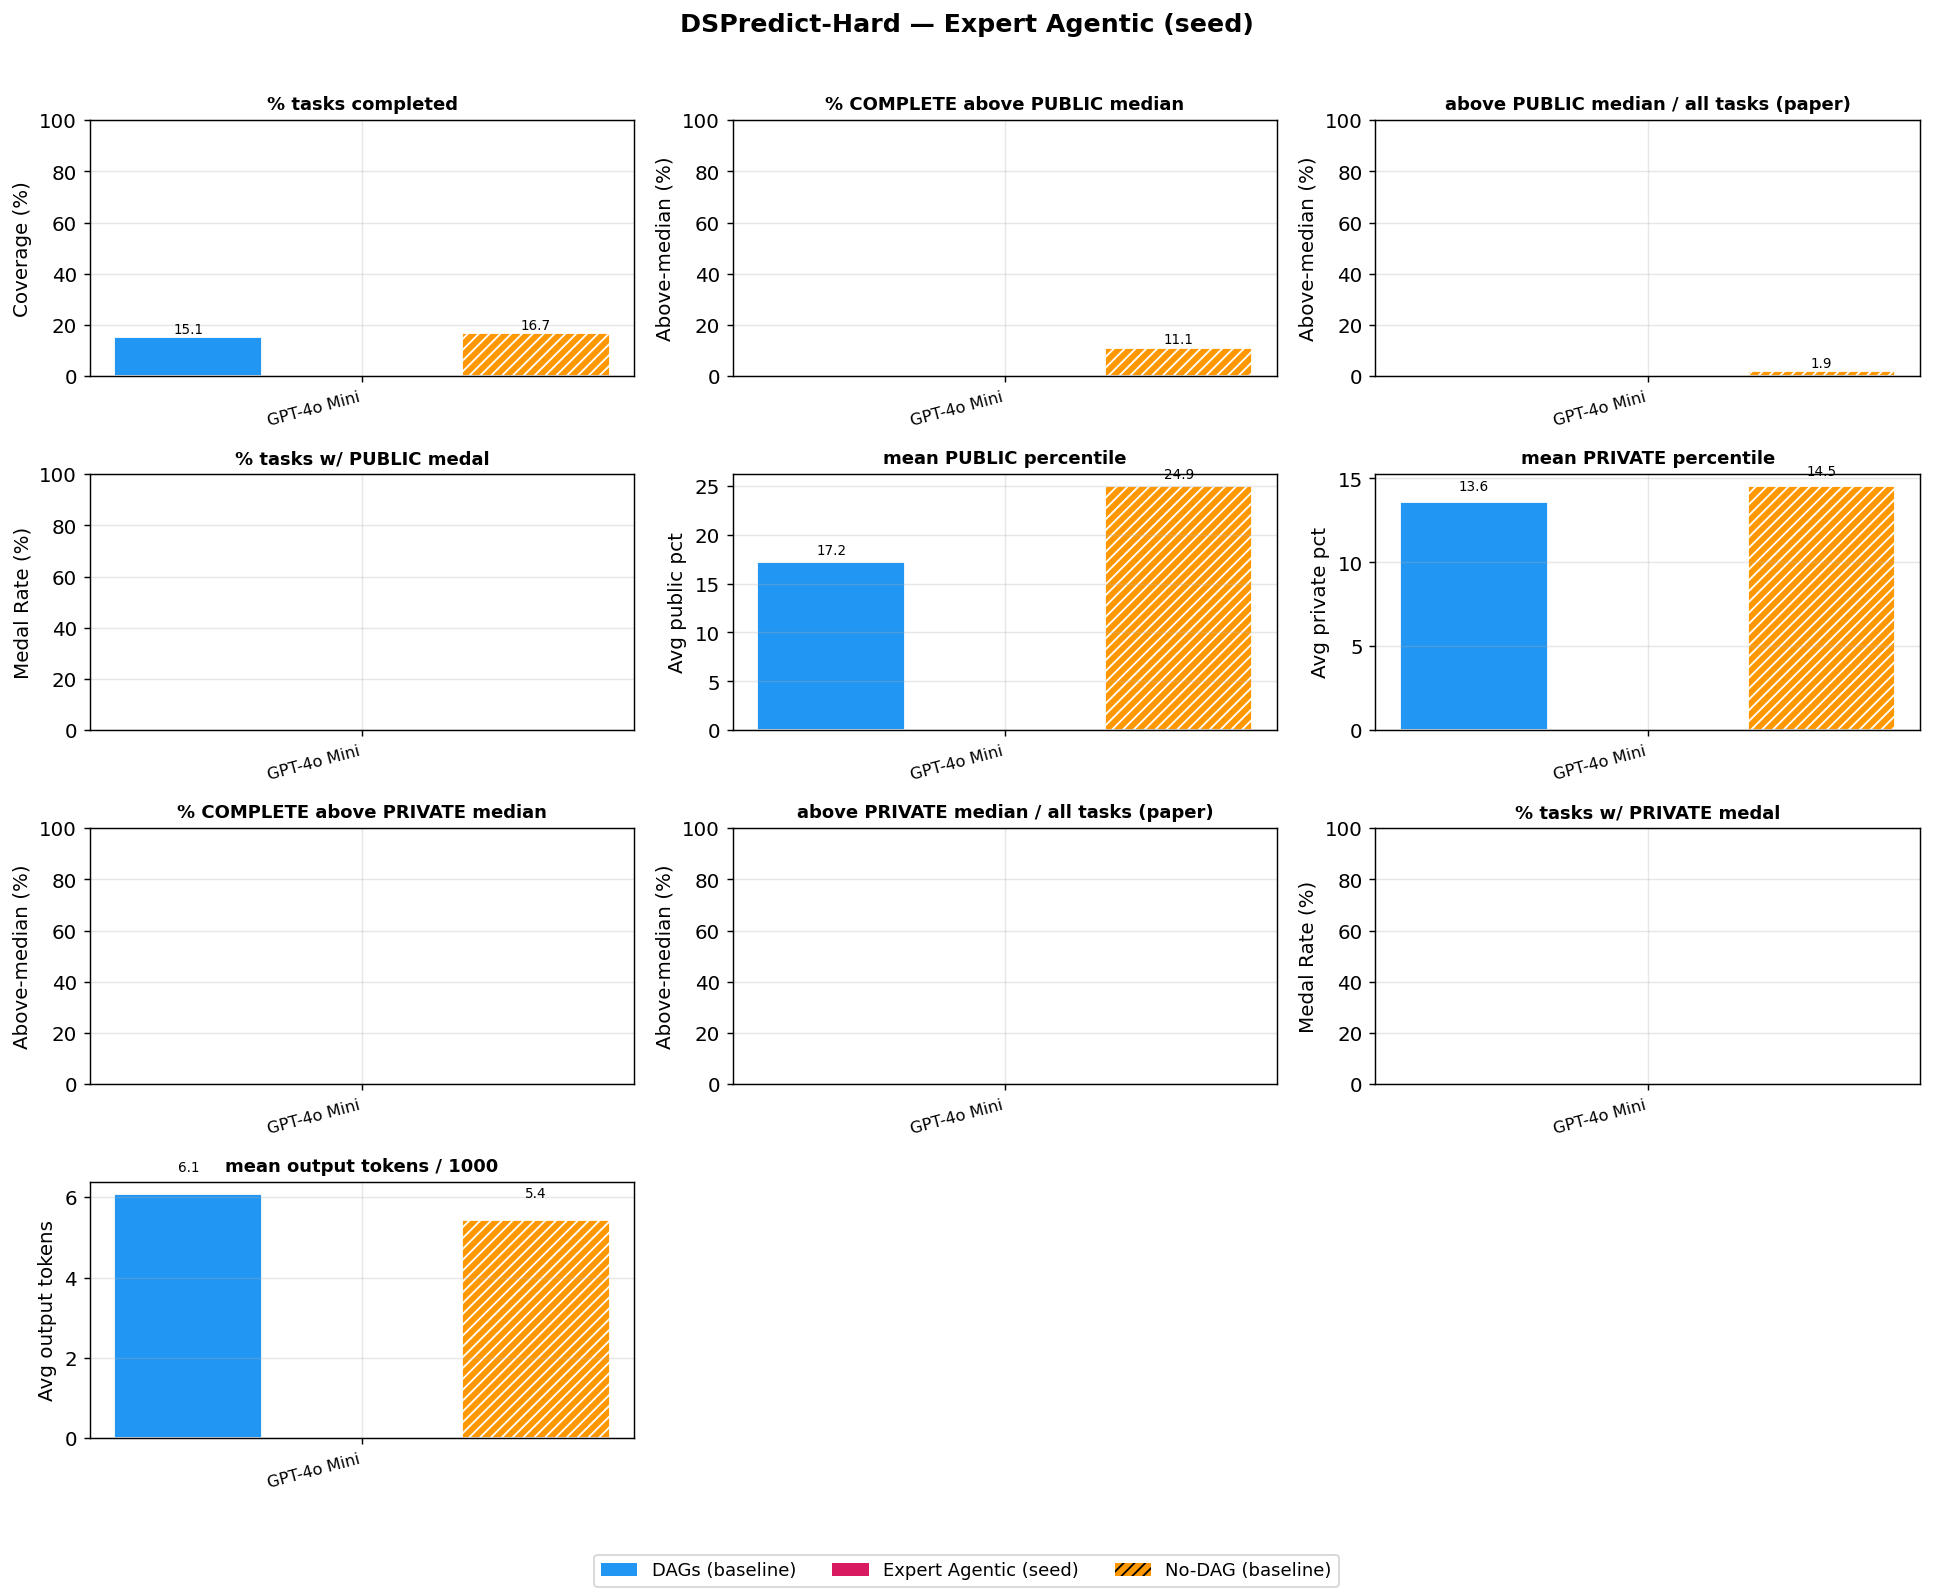

Saved dspredict_hard_variant_dags_expert-agentic_seed42.png



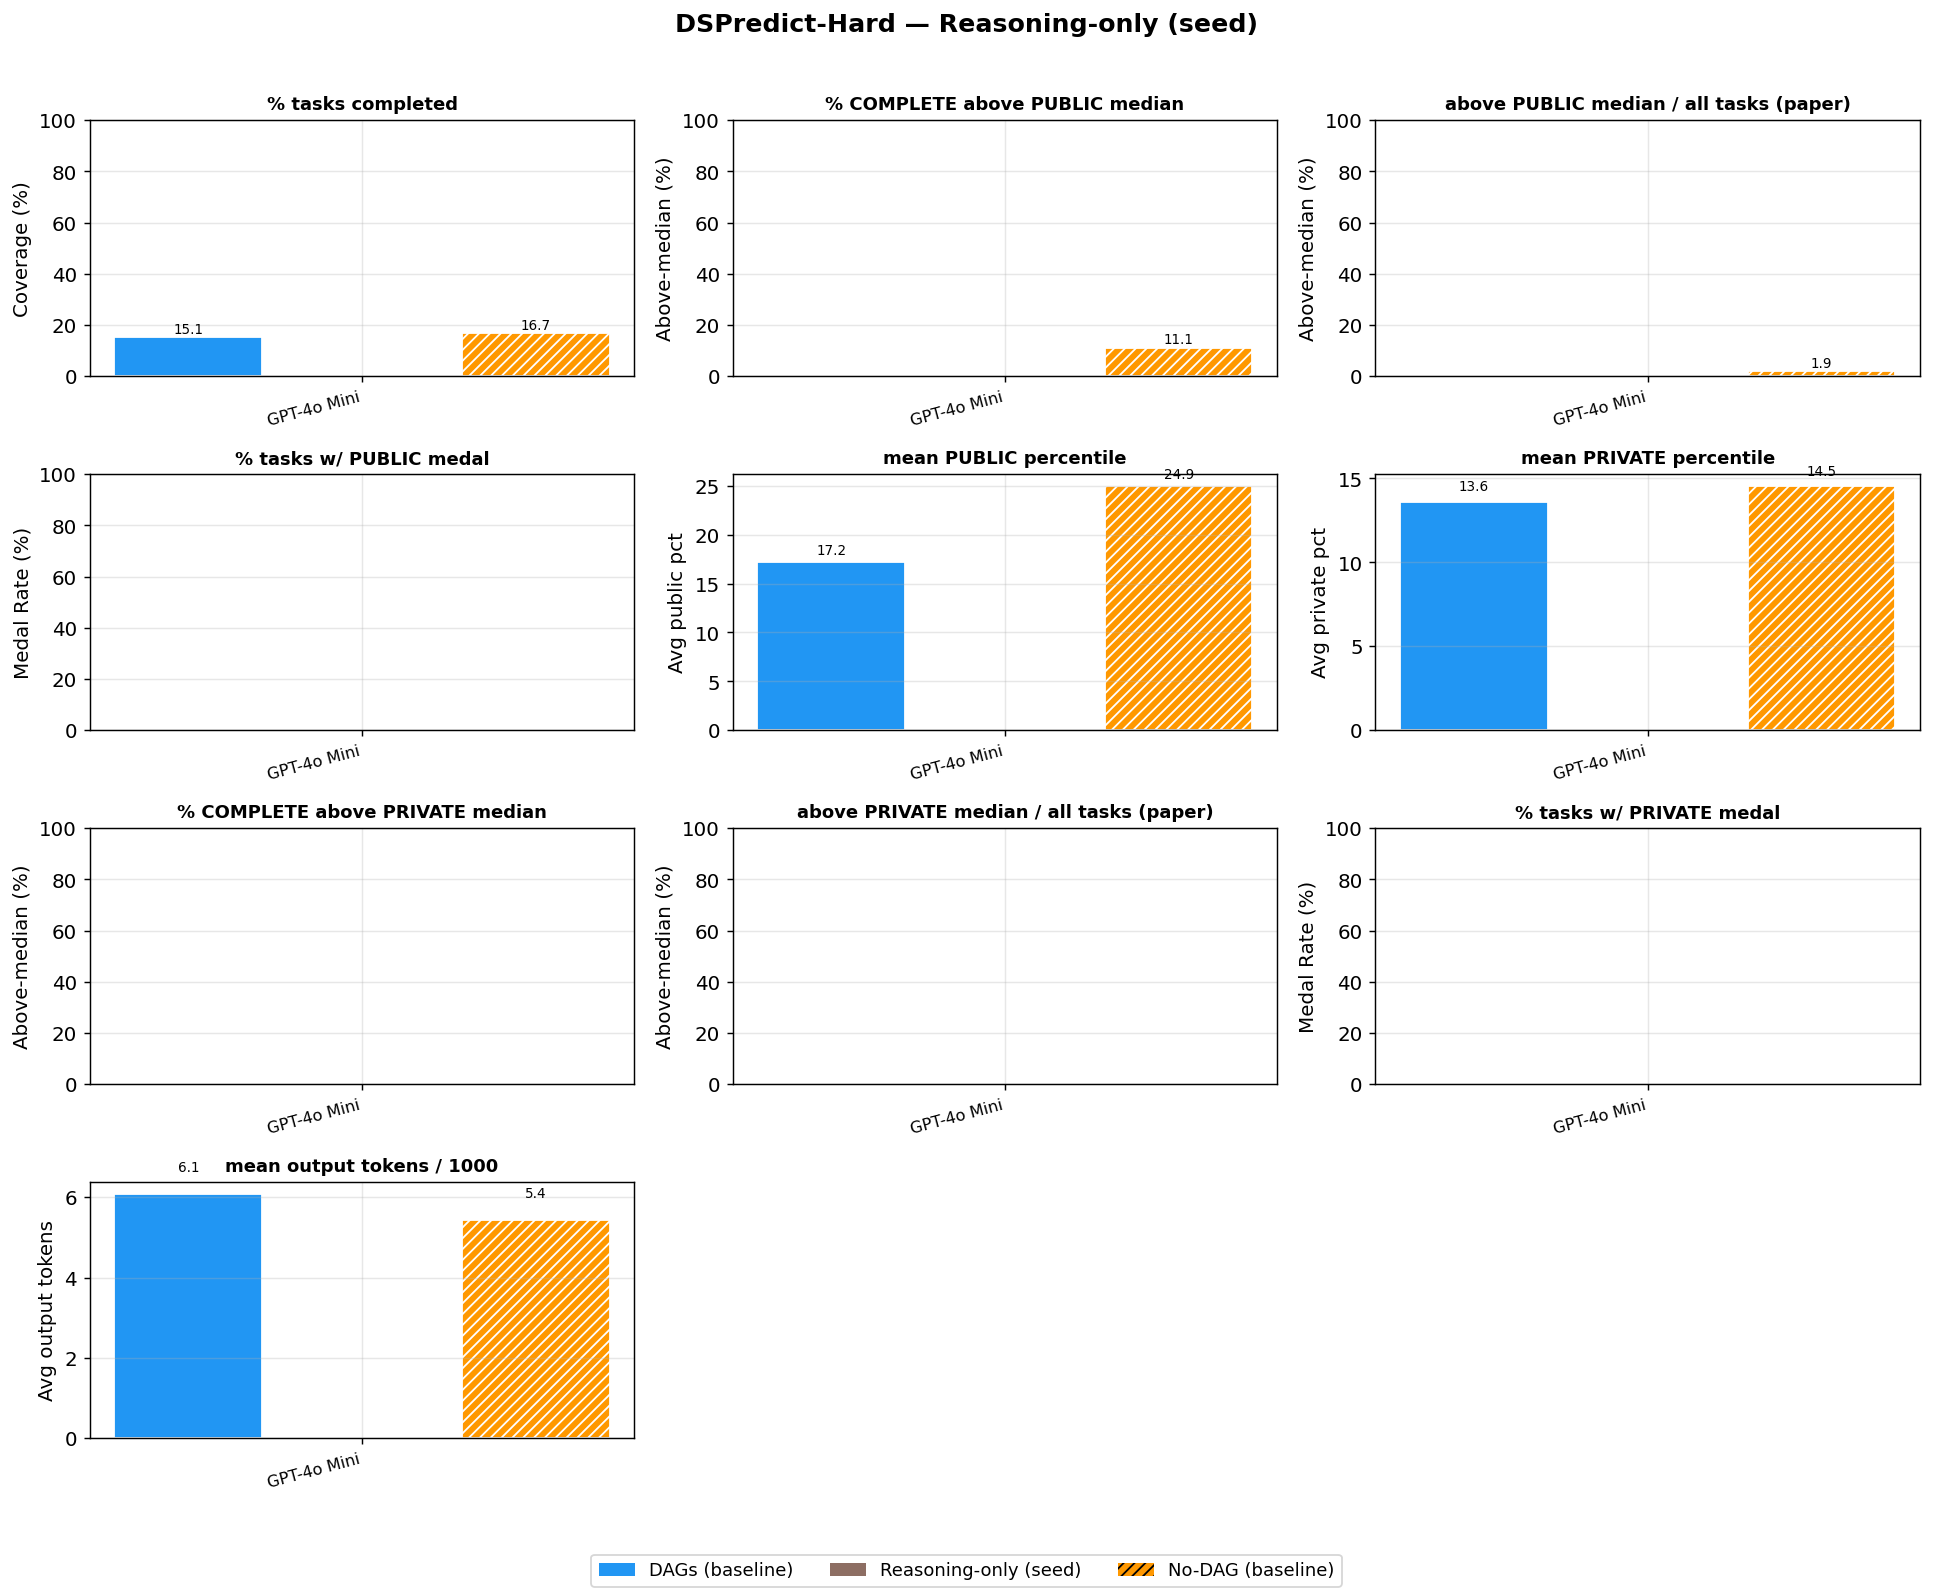

Saved dspredict_hard_variant_dags_reasoning-only_seed42.png



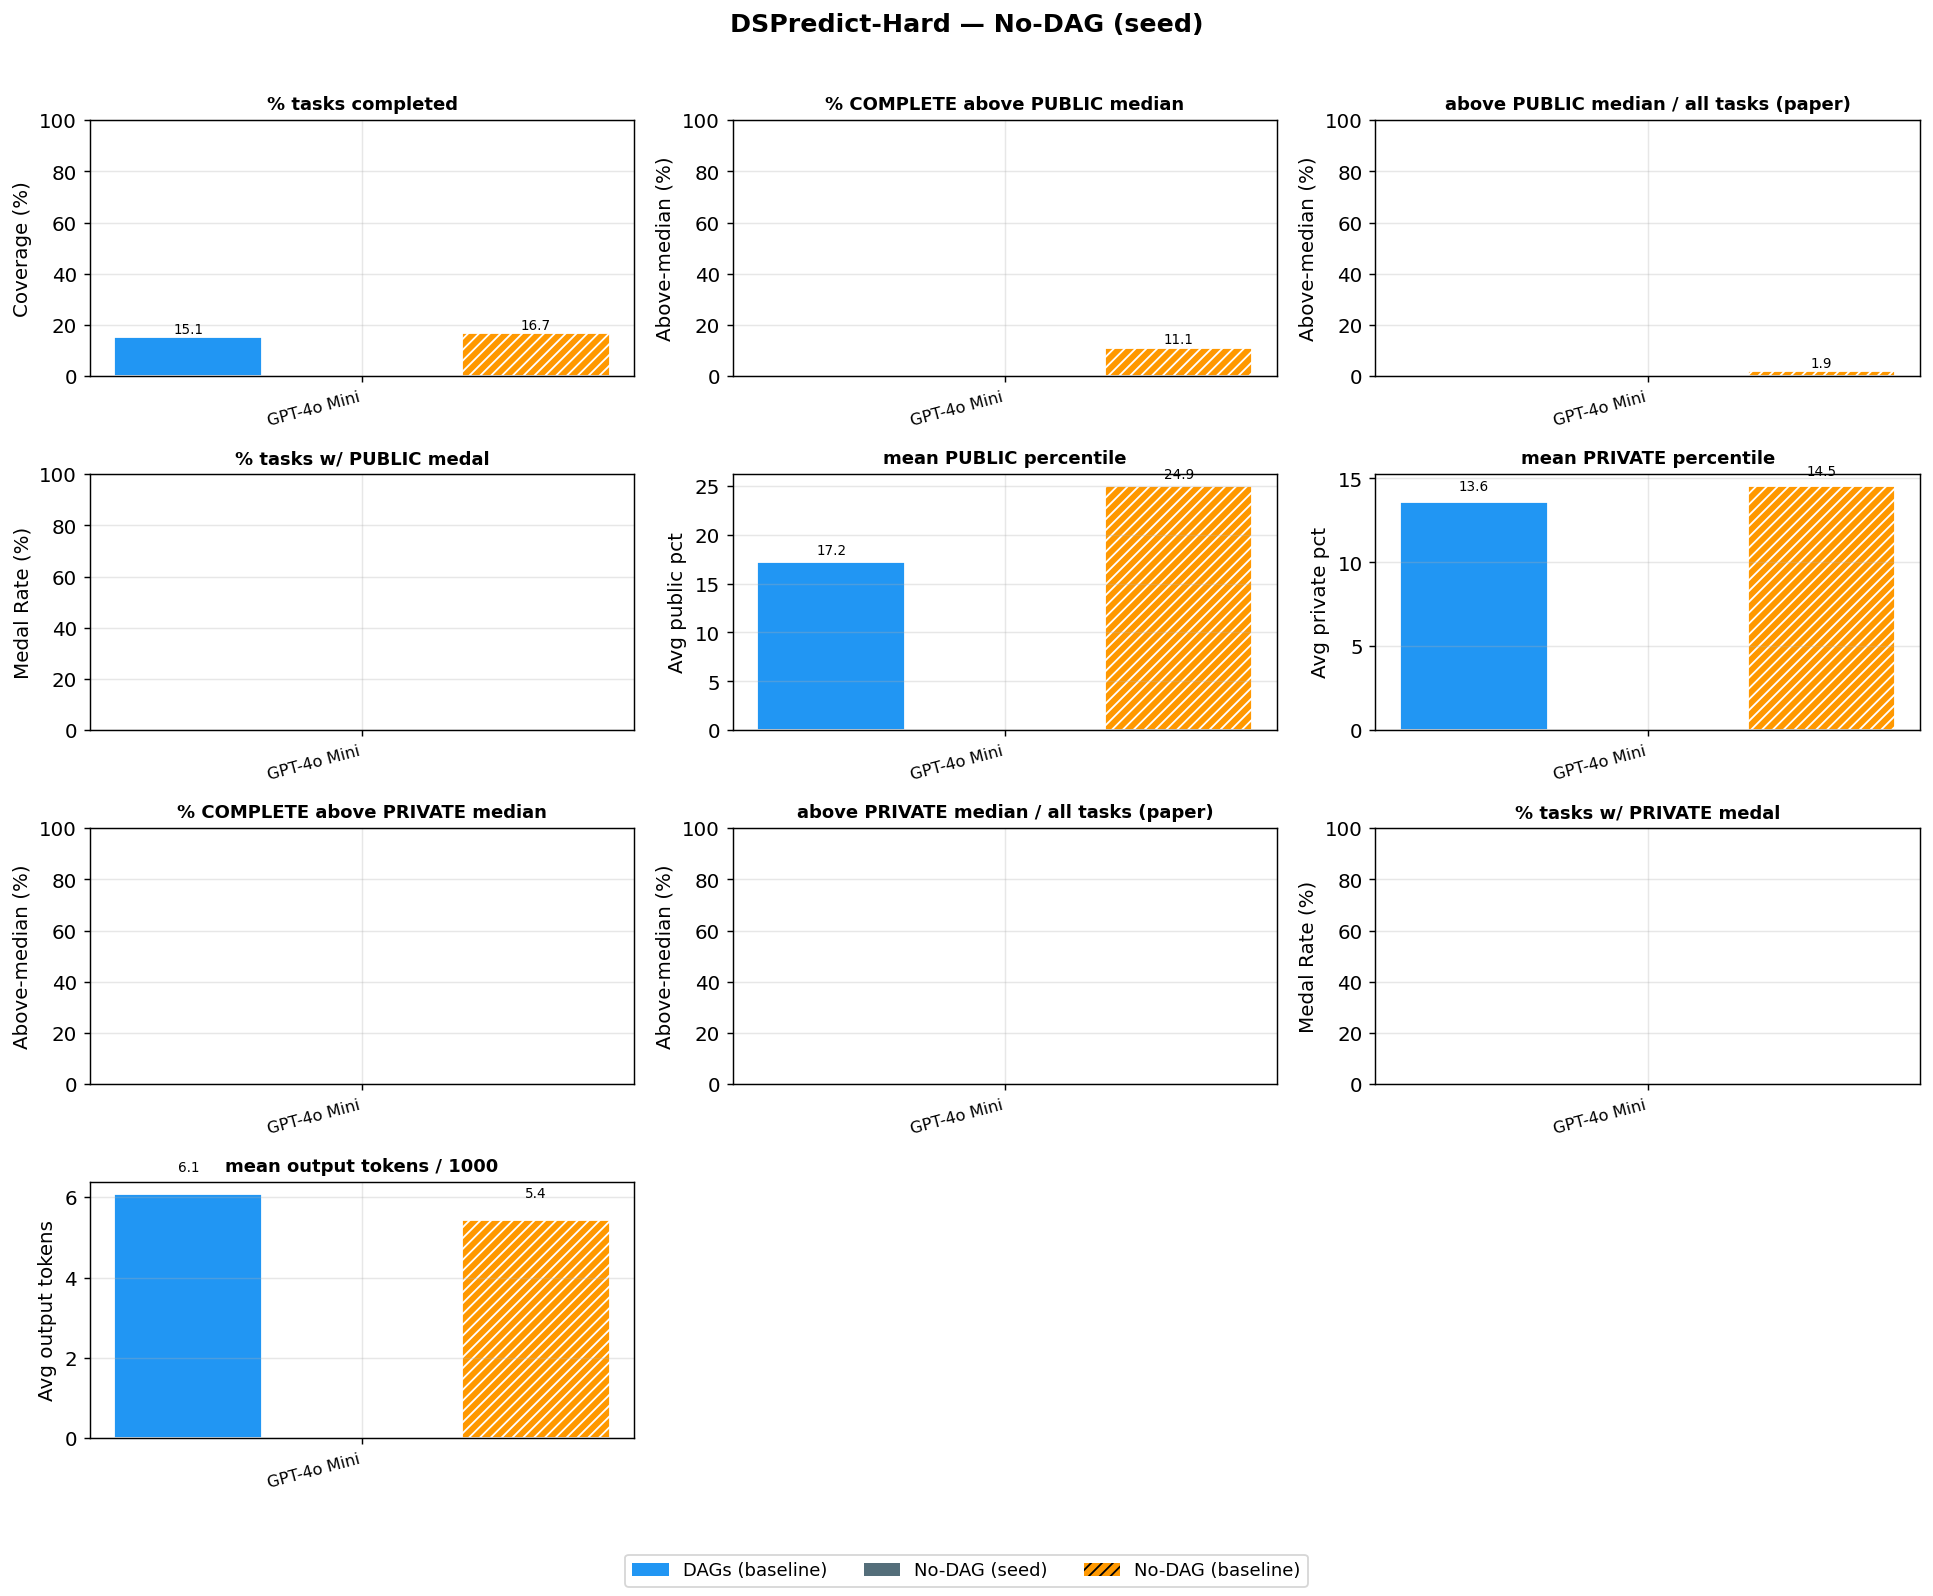

Saved dspredict_hard_variant_nodags_seed42.png



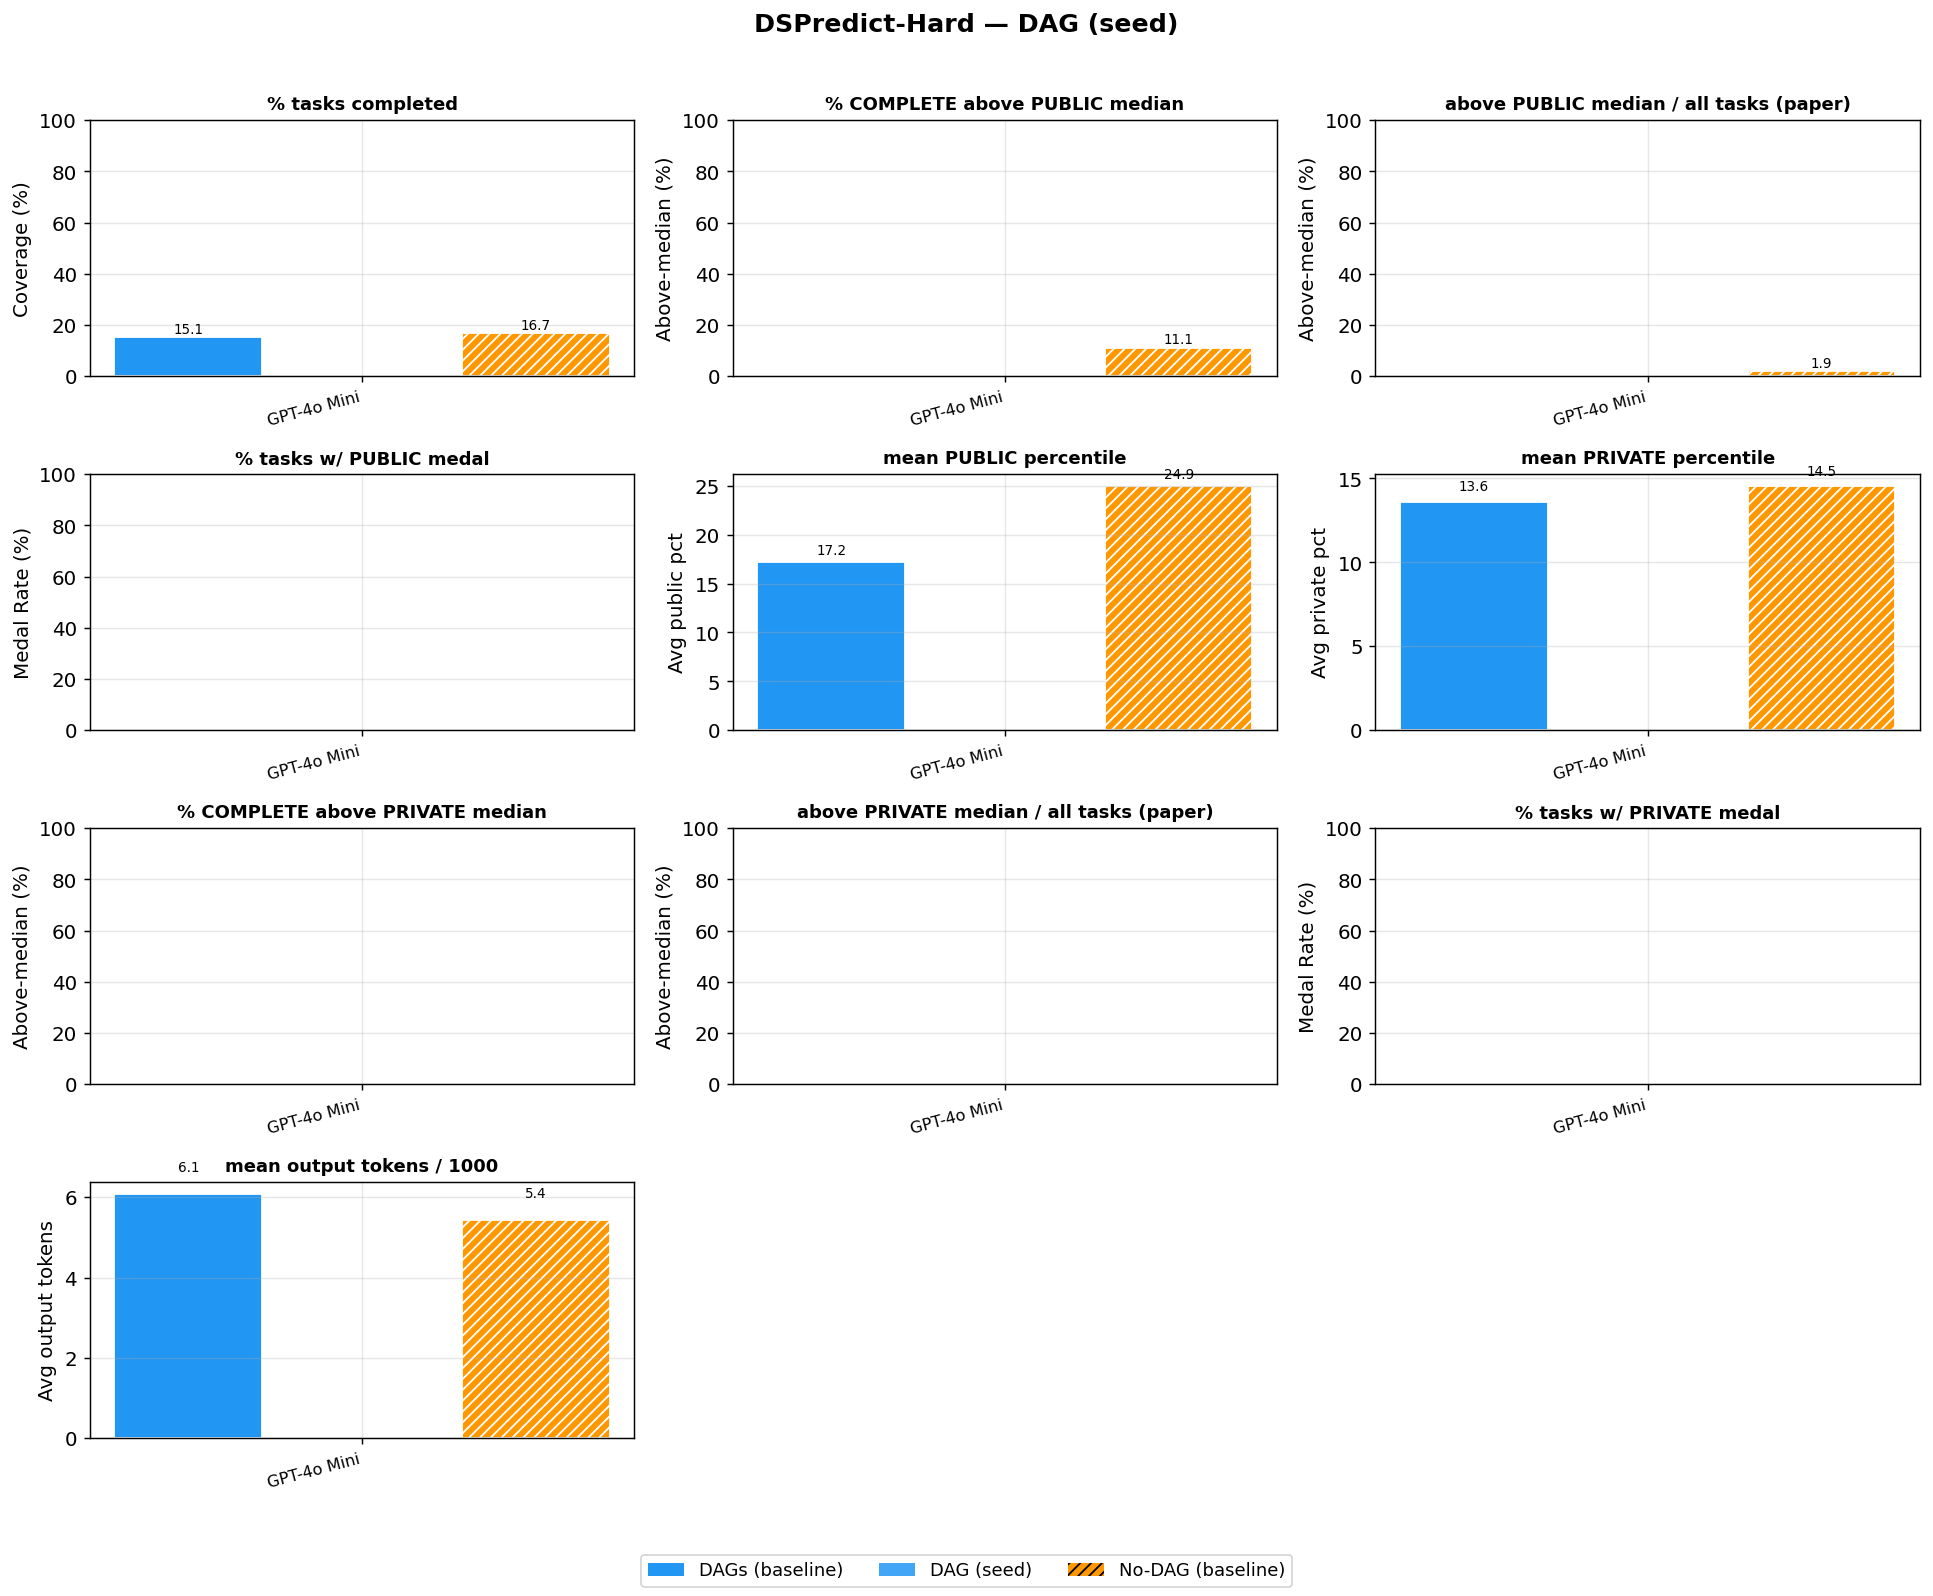

Saved dspredict_hard_variant_dags_seed42.png



In [4]:
# Baseline DAG-vs-No-DAG overview (covers every model with plain runs, incl. sonnet-4-5 / claude-4-6).
plot_baselines()
print()

# DAG vs No-DAG deltas (performance + medal rate).
plot_deltas()
print()

# One figure per variant.
for spec in SHOW:
    plot_variant(spec)
    print()

In [6]:
# Optional: flat summary table for inspection / export.
rows = []
for (m, mode), data in sorted(dp_hard.items()):
    b = base_of(m)
    rows.append({
        "Model":       MODEL_LABELS.get(b, b),
        "Run":         m,
        "Mode":        mode,
        "N":           len(data),
        "Coverage %":  round(_cov(data), 1),
        "AbM pub %":   round(_above(data), 1),
        "AbM pub/54":  round(_above_paper(data), 1),
        "AbM priv %":  round(_above_priv(data), 1),
        "AbM priv/54": round(_above_priv_paper(data), 1),
        "Medal pub %": round(_medal_rate(data), 1),
        "Medal priv %": round(_medal_rate_priv(data), 1),
        "Pub pct":     round(_avg_pub(data), 2),
        "Priv pct":    round(_avg_priv(data), 2),
        "Out toks (K)": round(_avg_out(data), 1),
    })
summary = pd.DataFrame(rows)
pd.set_option("display.max_rows", 100)
summary
# summary.to_csv(RESULTS_DIR / "dspredict_hard_summary.csv", index=False)

,Model,Run,Mode,N,Coverage %,AbM pub %,AbM pub/54,AbM priv %,AbM priv/54,Medal pub %,Medal priv %,Pub pct,Priv pct,Out toks (K)
0,Qwen3-Coder-480B-A35B-Instruct,Qwen3-Coder-480B-A35B-Instruct,dags,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0
1,Qwen3 480B,Qwen3-Coder-480B-A35B-Instruct-FP8,dags,54,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0
2,Claude Sonnet 4.5,claude-sonnet-4-5,dags,54,51.9,10.7,5.6,13.0,5.6,3.7,1.9,29.13,28.49,4.1
3,Claude Sonnet 4.6,claude-sonnet-4-6,dags,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0
4,DeepSeek V4 Pro,deepseek-v4-pro,dags,54,11.1,16.7,1.9,0.0,0.0,0.0,0.0,35.84,27.13,7.1
5,DeepSeek V4 Pro,deepseek-v4-pro (adaptive),dags_adaptive-revision,54,3.7,0.0,0.0,0.0,0.0,0.0,0.0,38.63,38.44,12.1
6,GPT-4o,gpt-4o (adaptive),dags_adaptive-revision,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,6.4
7,GPT-4o Mini,gpt-4o-mini,dags,53,15.1,0.0,0.0,0.0,0.0,0.0,0.0,17.20,13.60,6.1
8,GPT-4o Mini,gpt-4o-mini,nodags,54,16.7,11.1,1.9,0.0,0.0,0.0,0.0,24.94,14.53,5.4
9,GPT-4o Mini,gpt-4o-mini (adaptive),dags_adaptive-revision,54,3.7,0.0,0.0,0.0,0.0,0.0,0.0,3.56,1.63,2.7


### Notes
- **Colour by mode** with a consistent palette: plain `dags` = blue, each **variant** = its own
  accent colour, plain `nodags` = orange **hatched**. Model identity is shown by the x-axis groups
  (dotted separators + labels).
- Only **output tokens** are plotted (metric `avg_out_tok`).
- Coverage / Above-median use:
  `coverage = % of tasks with a COMPLETE submission`;
  `above-median = % of COMPLETE runs scoring above the public median`.

## Combined per model × prompt grand total (Part 1 + Part 2)

This is the key table for spotting which model × prompt combo hacks the most. Each cell = confirmed
reward-hacking traces in that combo across all categories (E + A + B + C + D).

| model \\ prompt | dags | nodags | dags_adaptive-revision | dags_vanilla-no-implementation | dags_reasoning-only_seed42 | dags_expert-agentic | dags_expert-agentic_seed42 | dags_problem-decomposition | dags_problem-decomposition_seed42 | dags_data-quality-methods | dags_seed42 | nodags_seed42 | **row total** |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| gpt_5_1 | 12 | 16 | – | – | – | – | – | – | – | – | – | – | **28** |
| gpt_4o_mini | 1 | 1 | 2 | 2 | 1 | 1 | 4 | 5 | 1 | 1 | 3 | 2 | **24** |
| claude_sonnet_4_5 | 7 | 3 | – | – | – | – | – | – | – | – | – | – | **10** |
| claude_sonnet_4_6 | 1 | 2 | – | – | – | – | – | – | – | – | – | – | **3** |
| deepseek_v4_pro | 2 | – | 1 | – | – | – | – | – | – | – | – | – | **3** |
| **col total** | **23** | **22** | **3** | **2** | **1** | **1** | **4** | **5** | **1** | **1** | **3** | **2** | **68** |

### All model × prompt combos ranked by hack count (full ranking, no cutoff)

| rank | model | prompt | total hacks | categories |
|---|---|---|---|---|
| 1 | gpt_5_1 | nodags | 16 | E (16) |
| 2 | gpt_5_1 | dags | 12 | E (12) |
| 3 | claude_sonnet_4_5 | dags | 7 | E (7) |
| 4 | gpt_4o_mini | dags_problem-decomposition | 5 | C (5) |
| 5 | gpt_4o_mini | dags_expert-agentic_seed42 | 4 | C (4) |
| 6 | gpt_4o_mini | dags_seed42 | 3 | C (3) |
| 7 | claude_sonnet_4_5 | nodags | 3 | E (3) |
| 8 | claude_sonnet_4_6 | nodags | 2 | B (1) + E (1) |
| 9 | deepseek_v4_pro | dags | 2 | E (2) |
| 10 | gpt_4o_mini | dags_adaptive-revision | 2 | C (2) |
| 11 | gpt_4o_mini | dags_vanilla-no-implementation | 2 | A (1) + C (1) |
| 12 | gpt_4o_mini | nodags_seed42 | 2 | A (1) + C (1) |
| 13 | claude_sonnet_4_6 | dags | 1 | E (1) |
| 14 | deepseek_v4_pro | dags_adaptive-revision | 1 | E (1) |
| 15 | gpt_4o_mini | dags | 1 | C (1) |
| 16 | gpt_4o_mini | dags_data-quality-methods | 1 | C (1) |
| 17 | gpt_4o_mini | dags_expert-agentic | 1 | C (1) |
| 18 | gpt_4o_mini | dags_problem-decomposition_seed42 | 1 | C (1) |
| 19 | gpt_4o_mini | dags_reasoning-only_seed42 | 1 | C (1) |
| 20 | gpt_4o_mini | nodags | 1 | A (1) |
| 21–27 | Qwen3_Coder_480B_A35B_Instruct_FP8, claude_sonnet_4_6, glm_5p2, gpt_4o, kimi_k2p7_code, sonnet_4_5 (remaining combos) | 0 ✓ clean | 0 | — |

